# Five Classifiers on MNIST & CIFAR-10 — From-Scratch vs. Transfer Learning

Five image classifiers evaluated on two datasets, with a full metric suite for each of the ten runs.

| # | Model | Family | Inductive bias / source of knowledge |
|---|---|---|---|
| 1 | **MLP** | from scratch | None. Flattens the image; spatial structure is destroyed. |
| 2 | **CNN** | from scratch | Locality + translation equivariance, hard-wired. |
| 3 | **ViT** | from scratch | Weak. Patch-level locality only; global relations must be learned. |
| 4 | **ResNet-50** | transfer (ImageNet) | Convolutional prior **plus** 1.28M labelled ImageNet images. |
| 5 | **ViT-B/16** | transfer (ImageNet) | Weak prior **plus** the same ImageNet supervision. |



## 1. Setup and imports

In [4]:
# !pip install torch torchvision matplotlib numpy

import time
import json
import copy
from pathlib import Path
from dataclasses import dataclass
from typing import Tuple, Dict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

# ---------------------------------------------------------------- switches
# QUICK_MODE: tiny subsets + 1-2 epochs. Use it to verify the notebook runs
# end to end in a couple of minutes before committing to the real thing.
# The sizes are absolute counts, deliberately independent of batch size, so
# every pipeline still sees the *same* images and the comparison stays valid.
QUICK_MODE  = False
QUICK_SIZES = dict(train=512, val=256, test=512)

# PRETRAINED: set False to build ResNet-50 / ViT-B-16 with random weights
# (no ~450 MB download). The transfer results become meaningless, but the
# plumbing still executes -- useful for offline testing.
PRETRAINED  = True

NUM_WORKERS = 2 if device.type == "cuda" else 0
USE_AMP     = device.type == "cuda"      # mixed precision, applied to every model

OUTDIR = Path("outputs")
FIGDIR = OUTDIR / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name, dpi=150):
    """Save a figure into outputs/figures/ and report where it went."""
    path = FIGDIR / f"{name}.png"
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    print(f"saved -> {path}")
    return path

print("PyTorch    :", torch.__version__)
print("Device     :", device)
print("AMP        :", USE_AMP)
print("Quick mode :", QUICK_MODE)
print("Pretrained :", PRETRAINED)

PyTorch    : 2.7.1+cu128
Device     : cuda
AMP        : True
Quick mode : False
Pretrained : True


## 2. Configuration

One config per dataset. Everything model-specific (patch size, channel widths, hidden sizes) lives here, so re-running the comparison at different capacities means editing one place.

The transfer block is deliberately separate. Fine-tuning a pretrained backbone needs its own resolution (224×224, non-negotiable for `vit_b_16` — its positional embeddings are sized for a 14×14 token grid), its own normalization (ImageNet statistics, because that is what the frozen features expect), a much shorter schedule, and a different learning rate. Forcing the from-scratch recipe onto it would not make the comparison fairer, only worse.

**`FREEZE_BACKBONE`** is the one knob worth understanding:

- `True` (default) — *linear probing*. The backbone is a fixed feature extractor; only a fresh linear head trains. Cheap, and it isolates the question "how good are ImageNet features for this dataset?"
- `False` — *full fine-tuning*. Every weight updates. Typically 2–5 points better on CIFAR-10, and several times slower.

In [5]:
IMAGENET_STATS = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))

FREEZE_BACKBONE = True     # True = linear probe, False = full fine-tune


@dataclass
class Config:
    name: str
    img_size: int
    in_channels: int
    patch_size: int
    num_classes: int = 10
    class_names: Tuple[str, ...] = tuple(str(i) for i in range(10))

    # --- ViT (from scratch) ---
    embed_dim: int = 128
    depth: int = 6
    num_heads: int = 8
    mlp_ratio: float = 4.0

    # --- CNN ---
    cnn_channels: Tuple[int, ...] = (32, 64, 128)

    # --- MLP ---
    mlp_hidden: Tuple[int, ...] = (1024, 512, 256)

    # --- shared training recipe (models 1-3) ---
    dropout: float = 0.1
    batch_size: int = 128
    epochs: int = 15
    lr: float = 3e-4
    weight_decay: float = 0.05
    val_fraction: float = 0.1

    # --- transfer recipe (models 4-5) ---
    tl_img_size: int = 224
    tl_batch_size: int = 64
    tl_epochs: int = 3
    tl_lr: float = 1e-3            # head-only -> a larger lr is appropriate
    tl_lr_backbone: float = 1e-5   # used only when FREEZE_BACKBONE is False
    tl_weight_decay: float = 1e-4
    tl_train_fraction: float = 1.0 # shrink to trade accuracy for wall-clock

    @property
    def num_patches(self):
        return (self.img_size // self.patch_size) ** 2

    @property
    def flat_dim(self):
        return self.in_channels * self.img_size ** 2


MNIST_CLASSES = tuple(str(i) for i in range(10))
CIFAR_CLASSES = ("airplane", "automobile", "bird", "cat", "deer",
                 "dog", "frog", "horse", "ship", "truck")

mnist_cfg = Config(name="MNIST",    img_size=28, in_channels=1, patch_size=7,
                   epochs=10, class_names=MNIST_CLASSES)
cifar_cfg = Config(name="CIFAR-10", img_size=32, in_channels=3, patch_size=4,
                   epochs=25, class_names=CIFAR_CLASSES)

CONFIGS = {"MNIST": mnist_cfg, "CIFAR-10": cifar_cfg}

if QUICK_MODE:
    for c in CONFIGS.values():
        c.epochs, c.tl_epochs = 2, 1

for c in CONFIGS.values():
    print(f"{c.name:<10} ViT tokens={c.num_patches:<4} MLP input dim={c.flat_dim:<5} "
          f"scratch epochs={c.epochs:<3} transfer epochs={c.tl_epochs}")

MNIST      ViT tokens=16   MLP input dim=784   scratch epochs=10  transfer epochs=3
CIFAR-10   ViT tokens=64   MLP input dim=3072  scratch epochs=25  transfer epochs=3


## 3. Data loading and splits

Torchvision gives the canonical train/test split. We carve a 10% **validation** set out of the training portion and hold the test set back entirely — it is touched once per model, after checkpoint selection.

The split indices are computed **once per dataset** and reused by both input pipelines. That matters: the scratch models and the transfer models must see the same images in the same roles, or the accuracy columns are not comparable at all. Two pipelines, one partition.

| | Models 1–3 (scratch) | Models 4–5 (transfer) |
|---|---|---|
| Resolution | native (28 / 32) | 224 × 224 |
| Channels | 1 (MNIST) / 3 | 3 (MNIST is replicated) |
| Normalization | per-dataset mean/std | ImageNet mean/std |
| Augmentation | crop + flip (CIFAR only) | crop + flip (CIFAR only) |

In [6]:
STATS = {
    "MNIST":    ((0.1307,), (0.3081,)),
    "CIFAR-10": ((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
}


def get_transforms(cfg, train=True):
    """Native-resolution pipeline for the from-scratch models."""
    mean, std = STATS[cfg.name]
    aug = []
    if train and cfg.name == "CIFAR-10":
        aug = [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()]
    return transforms.Compose(aug + [transforms.ToTensor(), transforms.Normalize(mean, std)])


def get_tl_transforms(cfg, train=True):
    """224x224 / 3-channel / ImageNet-normalized pipeline for the pretrained backbones."""
    mean, std = IMAGENET_STATS
    aug = []
    if train and cfg.name == "CIFAR-10":
        aug = [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()]
    resize = [transforms.Resize(cfg.tl_img_size)]
    if cfg.in_channels == 1:
        resize.append(transforms.Grayscale(num_output_channels=3))
    return transforms.Compose(aug + resize + [transforms.ToTensor(), transforms.Normalize(mean, std)])


_SPLIT_CACHE = {}

def get_split_indices(cfg, n_total):
    """One train/val partition per dataset, shared by both pipelines."""
    if cfg.name not in _SPLIT_CACHE:
        g = torch.Generator().manual_seed(SEED)
        perm = torch.randperm(n_total, generator=g).tolist()
        n_val = int(n_total * cfg.val_fraction)
        _SPLIT_CACHE[cfg.name] = (perm[n_val:], perm[:n_val])
    return _SPLIT_CACHE[cfg.name]


def build_loaders(cfg, transfer=False, root="./data"):
    ds_cls = datasets.MNIST if cfg.name == "MNIST" else datasets.CIFAR10
    tf = get_tl_transforms if transfer else get_transforms
    batch_size = cfg.tl_batch_size if transfer else cfg.batch_size

    train_full = ds_cls(root, train=True,  download=True, transform=tf(cfg, True))
    val_full   = ds_cls(root, train=True,  download=True, transform=tf(cfg, False))
    test_set   = ds_cls(root, train=False, download=True, transform=tf(cfg, False))

    train_idx, val_idx = get_split_indices(cfg, len(train_full))

    if QUICK_MODE:
        train_idx = train_idx[:QUICK_SIZES["train"]]
        val_idx   = val_idx[:QUICK_SIZES["val"]]
        test_set  = Subset(test_set, list(range(min(len(test_set), QUICK_SIZES["test"]))))
    elif transfer and cfg.tl_train_fraction < 1.0:
        # optional sub-sampling of the transfer training set (wall-clock control);
        # a prefix of the scratch training set, so the two remain nested
        train_idx = train_idx[:int(len(train_idx) * cfg.tl_train_fraction)]

    train_set = Subset(train_full, train_idx)
    val_set   = Subset(val_full,   val_idx)

    kw = dict(batch_size=batch_size, num_workers=NUM_WORKERS,
              pin_memory=(device.type == "cuda"))
    tag = "transfer" if transfer else "scratch "
    print(f"{cfg.name:<10} [{tag}] train={len(train_set):<6} val={len(val_set):<6} test={len(test_set)}")

    return (DataLoader(train_set, shuffle=True,  drop_last=True, **kw),
            DataLoader(val_set,   shuffle=False, **kw),
            DataLoader(test_set,  shuffle=False, **kw))


LOADERS    = {n: build_loaders(c, transfer=False) for n, c in CONFIGS.items()}
TL_LOADERS = {n: build_loaders(c, transfer=True)  for n, c in CONFIGS.items()}

MNIST      [scratch ] train=54000  val=6000   test=10000
CIFAR-10   [scratch ] train=45000  val=5000   test=10000
MNIST      [transfer] train=54000  val=6000   test=10000
CIFAR-10   [transfer] train=45000  val=5000   test=10000


### 3.1 Sample visualization

A look at what the models actually receive, and a class-balance check on the training split.

saved -> outputs\figures\samples_MNIST.png


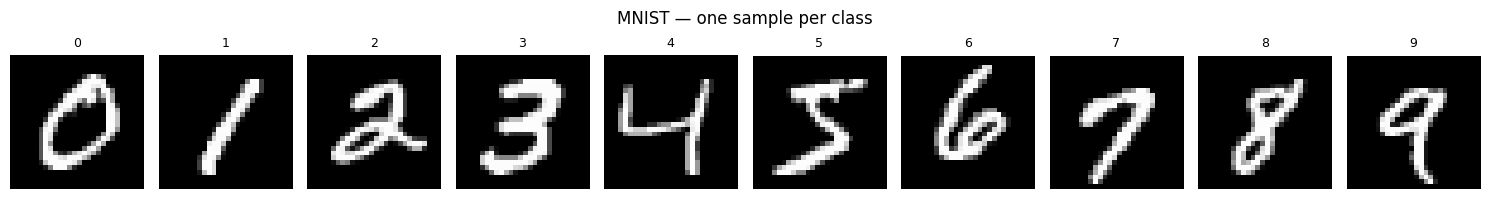

saved -> outputs\figures\samples_CIFAR-10.png


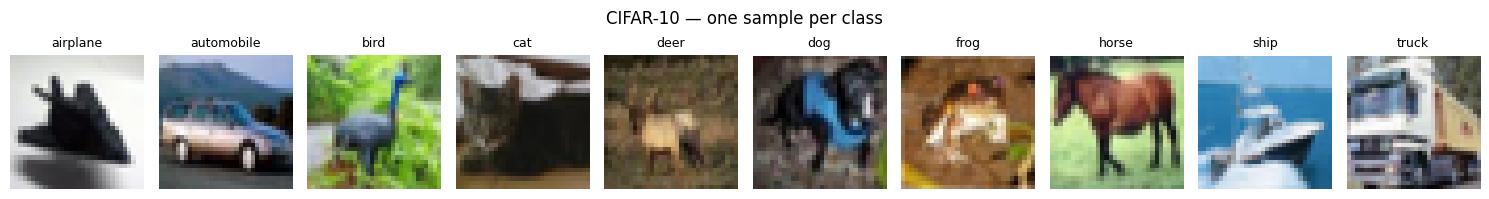

C:\Users\User\AppData\Local\Temp\ipykernel_35540\759757886.py:32: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  targets = np.array(raw.targets)


saved -> outputs\figures\class_balance.png


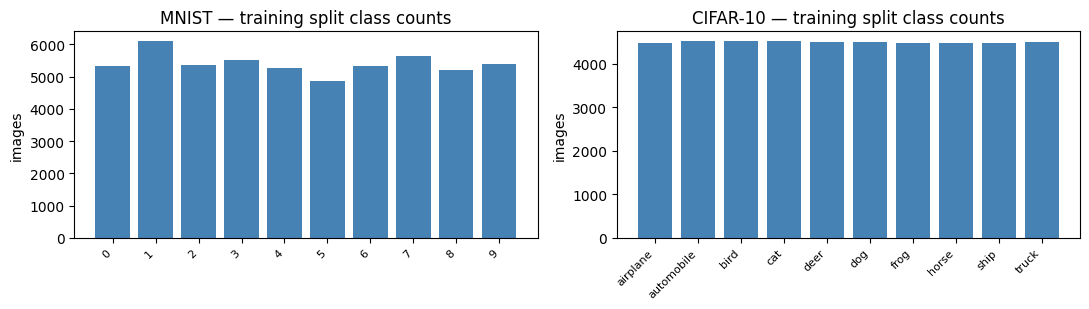

In [7]:
def show_samples(dataset_name, n=10):
    cfg = CONFIGS[dataset_name]
    ds_cls = datasets.MNIST if dataset_name == "MNIST" else datasets.CIFAR10
    raw = ds_cls("./data", train=True, download=True, transform=transforms.ToTensor())

    # one example per class
    picks, seen = [], set()
    for i in range(len(raw)):
        _, y = raw[i]
        if y not in seen:
            seen.add(y); picks.append(i)
        if len(seen) == n:
            break

    fig, axes = plt.subplots(1, n, figsize=(1.5 * n, 2.0))
    for ax, idx in zip(axes, sorted(picks, key=lambda i: raw[i][1])):
        img, y = raw[idx]
        ax.imshow(img.permute(1, 2, 0).squeeze(), cmap="gray" if cfg.in_channels == 1 else None)
        ax.set_title(cfg.class_names[y], fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{dataset_name} — one sample per class", fontsize=12)
    plt.tight_layout()
    savefig(fig, f"samples_{dataset_name}")
    plt.show()


def show_class_balance():
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    for ax, (dname, cfg) in zip(axes, CONFIGS.items()):
        ds_cls = datasets.MNIST if dname == "MNIST" else datasets.CIFAR10
        raw = ds_cls("./data", train=True, download=True)
        targets = np.array(raw.targets)
        train_idx, _ = get_split_indices(cfg, len(targets))
        counts = np.bincount(targets[np.array(train_idx)], minlength=10)
        ax.bar(range(10), counts, color="steelblue")
        ax.set_xticks(range(10))
        ax.set_xticklabels(cfg.class_names, rotation=45, ha="right", fontsize=8)
        ax.set_title(f"{dname} — training split class counts")
        ax.set_ylabel("images")
    plt.tight_layout()
    savefig(fig, "class_balance")
    plt.show()


for dname in CONFIGS:
    show_samples(dname)
show_class_balance()

## 4. Model 1 — Vision Transformer (from scratch)

A strided conv slices the image into non-overlapping patches and projects each to `embed_dim`, producing a token sequence. A learned `[CLS]` token is prepended and its final hidden state feeds the classifier. Encoder blocks use pre-norm residuals (`x + Attn(LN(x))`, then `x + MLP(LN(x))`), which trains more stably than the original post-norm form.

This is the small, dataset-native transformer — 6 layers, 128-dim, ~1M parameters. Compare it against §8, which is the same architecture family at 86M parameters with ImageNet behind it.

In [8]:
def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.trunc_normal_(m.weight, std=0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, (nn.LayerNorm, nn.BatchNorm2d, nn.BatchNorm1d)):
        nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    elif isinstance(m, nn.Conv2d):
        nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        if m.bias is not None:
            nn.init.zeros_(m.bias)


class PatchEmbedding(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.proj = nn.Conv2d(cfg.in_channels, cfg.embed_dim,
                              kernel_size=cfg.patch_size, stride=cfg.patch_size)

    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)   # (B, N, D)


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, dim, num_heads, dropout):
        super().__init__()
        assert dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.num_heads, self.head_dim = num_heads, dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        B, N, D = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = self.drop(((q @ k.transpose(-2, -1)) * self.scale).softmax(dim=-1))
        out = (attn @ v).transpose(1, 2).reshape(B, N, D)
        return self.drop(self.proj(out))


class EncoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        hidden = int(cfg.embed_dim * cfg.mlp_ratio)
        self.norm1 = nn.LayerNorm(cfg.embed_dim)
        self.attn  = MultiHeadSelfAttention(cfg.embed_dim, cfg.num_heads, cfg.dropout)
        self.norm2 = nn.LayerNorm(cfg.embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(cfg.embed_dim, hidden), nn.GELU(), nn.Dropout(cfg.dropout),
            nn.Linear(hidden, cfg.embed_dim), nn.Dropout(cfg.dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))


class VisionTransformer(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.patch_embed = PatchEmbedding(cfg)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, cfg.embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, cfg.num_patches + 1, cfg.embed_dim))
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([EncoderBlock(cfg) for _ in range(cfg.depth)])
        self.norm = nn.LayerNorm(cfg.embed_dim)
        self.head = nn.Linear(cfg.embed_dim, cfg.num_classes)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(init_weights)

    def forward(self, x):
        x = self.patch_embed(x)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = self.drop(torch.cat([cls, x], dim=1) + self.pos_embed)
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.norm(x)[:, 0])

## 5. Model 2 — CNN (from scratch)

Three conv blocks, each `Conv → BN → ReLU → Conv → BN → ReLU → MaxPool`, doubling channels while halving spatial resolution. Global average pooling replaces a large flatten-then-dense layer, which keeps the parameter count modest and the model resolution-agnostic.

Every convolution shares one kernel across all spatial positions — that weight sharing *is* the translation-equivariance prior, and it is the main reason this model beats the other two from-scratch models on CIFAR-10.

In [9]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch,  out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(dropout),
        )

    def forward(self, x):
        return self.block(x)


class CNN(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        chans = (cfg.in_channels,) + tuple(cfg.cnn_channels)
        self.features = nn.Sequential(*[
            ConvBlock(chans[i], chans[i + 1], cfg.dropout)
            for i in range(len(cfg.cnn_channels))
        ])
        self.pool = nn.AdaptiveAvgPool2d(1)     # global average pooling
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(cfg.dropout),
            nn.Linear(cfg.cnn_channels[-1], cfg.num_classes),
        )
        self.apply(init_weights)

    def forward(self, x):
        return self.head(self.pool(self.features(x)))

## 6. Model 3 — MLP (from scratch)

Flatten the image to a vector, then a stack of `Linear → BatchNorm → ReLU → Dropout` layers.

Note what flattening costs: pixel (0,0) and pixel (0,1) are adjacent in the image but the network has no way to know that — they are just input dimensions 0 and 1, no more related than dimensions 0 and 700. Every spatial relationship has to be rediscovered from data. It also means the first layer alone carries 3072×1024 ≈ 3.1M parameters on CIFAR-10, so this ends up the *largest* from-scratch model while performing worst.

In [10]:
class MLP(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        dims = (cfg.flat_dim,) + tuple(cfg.mlp_hidden)
        layers = [nn.Flatten()]
        for i in range(len(cfg.mlp_hidden)):
            layers += [
                nn.Linear(dims[i], dims[i + 1]),
                nn.BatchNorm1d(dims[i + 1]),
                nn.ReLU(inplace=True),
                nn.Dropout(cfg.dropout),
            ]
        layers.append(nn.Linear(dims[-1], cfg.num_classes))
        self.net = nn.Sequential(*layers)
        self.apply(init_weights)

    def forward(self, x):
        return self.net(x)

## 7. Model 4 — ResNet-50 transfer learning

Load ImageNet-pretrained ResNet-50, discard its 1000-way classifier, and attach a fresh 10-way linear head.

Two details that are easy to get wrong and quietly cost you accuracy:

**BatchNorm in a frozen backbone.** `requires_grad = False` stops the *weights* updating, but BatchNorm's running mean and variance are buffers, not parameters — they keep updating in `train()` mode regardless. Feeding upsampled MNIST through a frozen ResNet will happily overwrite ImageNet's carefully estimated statistics with digit statistics, and the "frozen" features drift. The `train()` override below pins the backbone to `eval()` so the buffers stay put.

**Wrapping the frozen forward in `no_grad`.** When nothing in the backbone needs gradients, storing activations for the backward pass is pure waste. This makes linear probing roughly 2–3× faster and cuts peak memory sharply.

In [11]:
class TransferBackbone(nn.Module):
    """Shared plumbing for the two pretrained models."""

    def __init__(self, freeze: bool):
        super().__init__()
        self.freeze = freeze

    def _freeze_backbone(self):
        if self.freeze:
            for p in self.backbone.parameters():
                p.requires_grad = False

    def train(self, mode=True):
        """Keep a frozen backbone in eval() so BN buffers / dropout stay fixed."""
        super().train(mode)
        if mode and self.freeze:
            self.backbone.eval()
        return self

    def extract(self, x):
        if self.freeze:
            with torch.no_grad():
                return self.backbone(x)
        return self.backbone(x)

    def forward(self, x):
        return self.head(self.extract(x))


class ResNet50Transfer(TransferBackbone):
    def __init__(self, cfg):
        super().__init__(freeze=FREEZE_BACKBONE)
        weights = models.ResNet50_Weights.IMAGENET1K_V2 if PRETRAINED else None
        self.backbone = models.resnet50(weights=weights)
        in_features = self.backbone.fc.in_features     # 2048
        self.backbone.fc = nn.Identity()               # expose pooled features
        self.head = nn.Linear(in_features, cfg.num_classes)
        nn.init.trunc_normal_(self.head.weight, std=0.01)
        nn.init.zeros_(self.head.bias)
        self._freeze_backbone()

## 8. Model 5 — Pretrained Vision Transformer (ViT-B/16) transfer learning

The same recipe applied to `vit_b_16`: 12 layers, 768-dim, 86M parameters, pretrained on ImageNet-1k.

The 224×224 input is a hard requirement here, not a preference. ViT-B/16 cuts the image into 16×16 patches and adds a *learned* positional embedding to each of the resulting 196 tokens. Change the resolution and the token count changes, and the positional embedding table no longer matches. (Torchvision ships `interpolate_embeddings` to resize that table if you ever need a different resolution — we simply upsample the inputs instead, which is the standard approach and needs no surgery.)

This is the direct counterpart to §4. Same architecture family, ~86× the parameters, and ImageNet supervision — worth holding side by side against the 1M-parameter version trained from scratch on 50k images.

In [12]:
class ViTB16Transfer(TransferBackbone):
    def __init__(self, cfg):
        super().__init__(freeze=FREEZE_BACKBONE)
        weights = models.ViT_B_16_Weights.IMAGENET1K_V1 if PRETRAINED else None
        self.backbone = models.vit_b_16(weights=weights)
        in_features = self.backbone.heads.head.in_features   # 768
        self.backbone.heads = nn.Identity()                  # expose the CLS embedding
        self.head = nn.Linear(in_features, cfg.num_classes)
        nn.init.trunc_normal_(self.head.weight, std=0.01)
        nn.init.zeros_(self.head.bias)
        self._freeze_backbone()

## 9. Registry and the shared training loop

Each model registers its constructor plus one flag: does it use the transfer pipeline or the scratch pipeline? Everything downstream — loaders, epoch count, learning rate — is derived from that flag, so no branch logic leaks into the training loop.

Within each family the recipe is identical:

| | Models 1–3 | Models 4–5 |
|---|---|---|
| Optimizer | AdamW | AdamW |
| Schedule | OneCycle, 10% warmup | OneCycle, 10% warmup |
| Loss | cross-entropy, label smoothing 0.1 | cross-entropy, label smoothing 0.1 |
| Grad clip | 1.0 | 1.0 |
| LR | `3e-4` | `1e-3` head / `1e-5` backbone |
| Epochs | 10 (MNIST) / 25 (CIFAR) | 3 |

Selection is always on **validation** accuracy; the test set is used exactly once per run, at the end.

In [13]:
@dataclass
class ModelSpec:
    ctor: type
    transfer: bool
    note: str


MODELS: Dict[str, ModelSpec] = {
    "MLP":            ModelSpec(MLP,               False, "scratch, flattened pixels"),
    "CNN":            ModelSpec(CNN,               False, "scratch, conv prior"),
    "ViT-scratch":    ModelSpec(VisionTransformer, False, "scratch, 6 layers / 128-dim"),
    "ResNet-50-TL":   ModelSpec(ResNet50Transfer,  True,  "ImageNet weights, 224px"),
    "ViT-B16-TL":     ModelSpec(ViTB16Transfer,    True,  "ImageNet weights, 224px"),
}

SCRATCH_MODELS  = [m for m, s in MODELS.items() if not s.transfer]
TRANSFER_MODELS = [m for m, s in MODELS.items() if s.transfer]


def count_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters()
               if p.requires_grad or not trainable_only)


def model_size_mb(m):
    """On-disk / in-memory footprint of weights + buffers."""
    p_bytes = sum(p.numel() * p.element_size() for p in m.parameters())
    b_bytes = sum(b.numel() * b.element_size() for b in m.buffers())
    return (p_bytes + b_bytes) / 1024 ** 2


def loaders_for(model_name, dataset_name):
    return (TL_LOADERS if MODELS[model_name].transfer else LOADERS)[dataset_name]


# ---- sanity check: every model produces (B, 10) on every dataset ----
print(f"{'Model':<15}{'Dataset':<11}{'Input':<18}{'Output':<10}{'Total':>10}{'Trainable':>12}{'Size':>10}")
print("-" * 86)
for mname, spec in MODELS.items():
    for dname, cfg in CONFIGS.items():
        m = spec.ctor(cfg)
        side = cfg.tl_img_size if spec.transfer else cfg.img_size
        ch   = 3 if spec.transfer else cfg.in_channels
        x = torch.randn(2, ch, side, side)
        m.eval()
        with torch.no_grad():
            out = m(x)
        print(f"{mname:<15}{dname:<11}{str((2, ch, side, side)):<18}{str(tuple(out.shape)):<10}"
              f"{count_params(m)/1e6:9.2f}M{count_params(m, True)/1e6:11.2f}M"
              f"{model_size_mb(m):9.1f}MB")
        del m

Model          Dataset    Input             Output         Total   Trainable      Size
--------------------------------------------------------------------------------------
MLP            MNIST      (2, 1, 28, 28)    (2, 10)        1.47M       1.47M      5.6MB
MLP            CIFAR-10   (2, 3, 32, 32)    (2, 10)        3.81M       3.81M     14.5MB
CNN            MNIST      (2, 1, 28, 28)    (2, 10)        0.29M       0.29M      1.1MB
CNN            CIFAR-10   (2, 3, 32, 32)    (2, 10)        0.29M       0.29M      1.1MB
ViT-scratch    MNIST      (2, 1, 28, 28)    (2, 10)        1.20M       1.20M      4.6MB
ViT-scratch    CIFAR-10   (2, 3, 32, 32)    (2, 10)        1.21M       1.21M      4.6MB
ResNet-50-TL   MNIST      (2, 3, 224, 224)  (2, 10)       23.53M       0.02M     90.0MB
ResNet-50-TL   CIFAR-10   (2, 3, 224, 224)  (2, 10)       23.53M       0.02M     90.0MB
ViT-B16-TL     MNIST      (2, 3, 224, 224)  (2, 10)       85.81M       0.01M    327.3MB
ViT-B16-TL     CIFAR-10   (2, 3, 2

## 10. Evaluation metrics

Everything in task 6, computed from one confusion matrix so the numbers cannot disagree with each other.

- **Accuracy** — `trace(CM) / sum(CM)`
- **Precision** (per class *c*) — `CM[c,c] / column_sum(c)`: of everything predicted *c*, how much was really *c*
- **Recall** (per class *c*) — `CM[c,c] / row_sum(c)`: of everything that was really *c*, how much did we catch
- **F1** — harmonic mean of the two
- **Macro average** — unweighted mean over classes, so a rare class counts as much as a common one
- **Weighted average** — mean weighted by support; on these two balanced datasets it will nearly equal accuracy

Definitions match `sklearn.metrics` with `zero_division=0`, implemented directly here so the notebook has no extra dependency.

**Inference time** is measured on the test set after two warm-up batches, with CUDA synchronization around each forward pass, and covers the forward pass only — not disk I/O or host→device copies. Note that models 4–5 are timed on 224×224 inputs and models 1–3 on native resolution, which is a real part of their deployment cost, not an artifact.

In [14]:
def confusion_matrix(y_true, y_pred, n_classes=10):
    cm = np.zeros((n_classes, n_classes), dtype=np.int64)
    np.add.at(cm, (y_true, y_pred), 1)      # rows = true, cols = predicted
    return cm


def classification_metrics(cm):
    """Per-class and averaged precision / recall / F1 from a confusion matrix."""
    tp        = np.diag(cm).astype(np.float64)
    support   = cm.sum(axis=1).astype(np.float64)   # true occurrences
    predicted = cm.sum(axis=0).astype(np.float64)   # predicted occurrences

    precision = np.divide(tp, predicted, out=np.zeros_like(tp), where=predicted > 0)
    recall    = np.divide(tp, support,   out=np.zeros_like(tp), where=support   > 0)
    denom     = precision + recall
    f1        = np.divide(2 * precision * recall, denom, out=np.zeros_like(tp), where=denom > 0)

    w = support / support.sum()
    return {
        "accuracy":            float(tp.sum() / cm.sum()),
        "precision_per_class": precision.tolist(),
        "recall_per_class":    recall.tolist(),
        "f1_per_class":        f1.tolist(),
        "support_per_class":   support.astype(int).tolist(),
        "precision_macro":     float(precision.mean()),
        "recall_macro":        float(recall.mean()),
        "f1_macro":            float(f1.mean()),
        "precision_weighted":  float((precision * w).sum()),
        "recall_weighted":     float((recall * w).sum()),
        "f1_weighted":         float((f1 * w).sum()),
    }


@torch.no_grad()
def predict_and_time(model, loader, warmup_batches=2):
    """Collect predictions over a loader and time the forward pass."""
    model.eval()
    y_true, y_pred = [], []
    total_time, timed_images = 0.0, 0
    all_time, all_images = 0.0, 0

    for i, (x, y) in enumerate(loader):
        x = x.to(device, non_blocking=True)

        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        with torch.amp.autocast(device.type, enabled=USE_AMP):
            logits = model(x)
        if device.type == "cuda":
            torch.cuda.synchronize()
        dt = time.perf_counter() - t0

        all_time += dt; all_images += x.size(0)
        if i >= warmup_batches:                  # discard warm-up batches
            total_time  += dt
            timed_images += x.size(0)

        y_pred.append(logits.float().argmax(1).cpu())
        y_true.append(y)

    # a test set smaller than the warmup window leaves nothing timed -- use everything
    if timed_images == 0:
        total_time, timed_images = all_time, all_images

    y_true = torch.cat(y_true).numpy()
    y_pred = torch.cat(y_pred).numpy()
    ms_per_image = (total_time / timed_images) * 1000
    return y_true, y_pred, ms_per_image, timed_images / total_time


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Loss + accuracy, used for per-epoch validation."""
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.amp.autocast(device.type, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        loss_sum += loss.item() * y.size(0)
        correct  += (logits.argmax(1) == y).sum().item()
        total    += y.size(0)
    return loss_sum / total, correct / total

## 11. Training loop

One loop for all five models. The only thing that varies is which loader set and which hyperparameter block gets pulled out of the config, both decided by the model's `transfer` flag.

Checkpointing note: when the backbone is frozen, only the head is worth saving — snapshotting all 86M ViT-B/16 parameters every time validation improves would waste around 344 MB per copy for weights that never change.

In [15]:
def build_optimizer(model, cfg, spec):
    """AdamW with the appropriate parameter groups; returns (optimizer, max_lr)."""
    if not spec.transfer:
        opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
        return opt, cfg.lr

    head_params = list(model.head.parameters())
    if FREEZE_BACKBONE:
        groups, max_lr = [{"params": head_params, "lr": cfg.tl_lr}], cfg.tl_lr
    else:
        backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
        groups = [{"params": head_params,     "lr": cfg.tl_lr},
                  {"params": backbone_params, "lr": cfg.tl_lr_backbone}]
        max_lr = [cfg.tl_lr, cfg.tl_lr_backbone]
    return torch.optim.AdamW(groups, weight_decay=cfg.tl_weight_decay), max_lr


def snapshot(model, spec):
    if spec.transfer and FREEZE_BACKBONE:
        return ("head", copy.deepcopy(model.head.state_dict()))
    return ("full", {k: v.detach().cpu().clone() for k, v in model.state_dict().items()})


def restore(model, snap):
    kind, state = snap
    (model.head if kind == "head" else model).load_state_dict(state)


def train_model(model_name, dataset_name, verbose=True, loaders=None, variant="baseline"):
    """Train one model on one dataset.

    `loaders` overrides the default pipeline, which is what the augmentation
    ablation in section 17 uses to swap the training transform while keeping
    every other detail of this loop identical.
    """
    spec = MODELS[model_name]
    cfg  = CONFIGS[dataset_name]
    train_loader, val_loader, test_loader = loaders or loaders_for(model_name, dataset_name)
    epochs = cfg.tl_epochs if spec.transfer else cfg.epochs

    torch.manual_seed(SEED)                       # identical init seed per run
    model = spec.ctor(cfg).to(device)

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer, max_lr = build_optimizer(model, cfg, spec)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=max_lr, epochs=epochs,
        steps_per_epoch=len(train_loader), pct_start=0.1
    )
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "epoch_time": []}
    best_acc, best_snap = -1.0, None
    t_start = time.time()

    for epoch in range(1, epochs + 1):
        t_epoch = time.time()
        model.train()
        loss_sum, correct, total = 0.0, 0, 0

        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(device.type, enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            loss_sum += loss.item() * y.size(0)
            correct  += (logits.argmax(1) == y).sum().item()
            total    += y.size(0)

        tr_loss, tr_acc = loss_sum / total, correct / total
        va_loss, va_acc = evaluate(model, val_loader, criterion)
        epoch_time = time.time() - t_epoch

        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)
        history["epoch_time"].append(epoch_time)

        if va_acc > best_acc:
            best_acc, best_snap = va_acc, snapshot(model, spec)

        if verbose:
            print(f"  epoch {epoch:2d}/{epochs} | train {tr_loss:.4f}/{tr_acc*100:5.2f}% "
                  f"| val {va_loss:.4f}/{va_acc*100:5.2f}% | {epoch_time:.1f}s")

    train_time = time.time() - t_start

    # ---- test the best-validation checkpoint, once ----
    restore(model, best_snap)
    y_true, y_pred, ms_per_image, throughput = predict_and_time(model, test_loader)
    cm = confusion_matrix(y_true, y_pred, cfg.num_classes)
    metrics = classification_metrics(cm)

    result = {
        "model": model_name,
        "dataset": dataset_name,
        "variant": variant,
        "transfer": spec.transfer,
        "params_total": count_params(model),
        "params_trainable": count_params(model, trainable_only=True),
        "size_mb": model_size_mb(model),
        "best_val_acc": best_acc,
        "train_time_s": train_time,
        "mean_epoch_s": float(np.mean(history["epoch_time"])),
        "epochs": epochs,
        "infer_ms_per_image": ms_per_image,
        "infer_images_per_s": throughput,
        "history": history,
        "confusion_matrix": cm.tolist(),
        "y_true": y_true.tolist(),
        "y_pred": y_pred.tolist(),
        **metrics,
    }

    del model, best_snap
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return result

## 12. Run all ten combinations

5 models × 2 datasets.

**Expect this to take a while.** On a single modern GPU with `FREEZE_BACKBONE = True`, budget roughly 30–50 minutes. On CPU the transfer models are impractical — set `QUICK_MODE = True` in §1, or lower `tl_train_fraction` in §2, or skip models 4–5 entirely. Full fine-tuning (`FREEZE_BACKBONE = False`) multiplies the transfer runs several times over.

In [16]:
results = {}

for dataset_name in CONFIGS:
    for model_name in MODELS:
        print(f"\n{'='*66}\n{model_name} on {dataset_name}  ({MODELS[model_name].note})\n{'='*66}")
        res = train_model(model_name, dataset_name, verbose=True)
        results[(model_name, dataset_name)] = res
        print(f"  -> best val {res['best_val_acc']*100:.2f}% | TEST {res['accuracy']*100:.2f}% | "
              f"F1 {res['f1_macro']*100:.2f}% | {res['params_total']/1e6:.1f}M params | "
              f"{res['size_mb']:.0f}MB | {res['train_time_s']:.0f}s train | "
              f"{res['infer_ms_per_image']:.2f}ms/img")

# ---- persist everything so the analysis below can be re-run without retraining ----
OUTDIR.mkdir(parents=True, exist_ok=True)
with open(OUTDIR / "results.json", "w") as f:
    json.dump({f"{m}|{d}": v for (m, d), v in results.items()}, f, indent=2)
print(f"\nsaved -> {OUTDIR / 'results.json'}")


MLP on MNIST  (scratch, flattened pixels)
  epoch  1/10 | train 1.0692/82.02% | val 0.6158/96.27% | 11.1s
  epoch  2/10 | train 0.5971/97.23% | val 0.5732/97.82% | 10.8s
  epoch  3/10 | train 0.5638/98.40% | val 0.5635/97.85% | 16.4s
  epoch  4/10 | train 0.5473/99.05% | val 0.5543/98.17% | 16.1s
  epoch  5/10 | train 0.5366/99.41% | val 0.5508/98.35% | 10.6s
  epoch  6/10 | train 0.5296/99.59% | val 0.5468/98.30% | 10.8s
  epoch  7/10 | train 0.5237/99.80% | val 0.5445/98.52% | 16.6s
  epoch  8/10 | train 0.5202/99.86% | val 0.5429/98.52% | 16.6s
  epoch  9/10 | train 0.5188/99.91% | val 0.5419/98.50% | 11.7s
  epoch 10/10 | train 0.5182/99.90% | val 0.5423/98.50% | 12.4s
  -> best val 98.52% | TEST 98.64% | F1 98.63% | 1.5M params | 6MB | 133s train | 0.04ms/img

CNN on MNIST  (scratch, conv prior)
  epoch  1/10 | train 1.5852/59.13% | val 0.6525/96.97% | 11.4s
  epoch  2/10 | train 0.6276/97.62% | val 0.5765/98.37% | 11.1s
  epoch  3/10 | train 0.5798/98.69% | val 0.5537/98.95% | 1

## 13. Results tables

In [17]:
import csv

MODEL_ORDER   = list(MODELS.keys())
DATASET_ORDER = list(CONFIGS.keys())
COLORS = dict(zip(MODEL_ORDER, plt.rcParams["axes.prop_cycle"].by_key()["color"]))

HEADER = ["Dataset", "Model", "Params(M)", "Train(M)", "Size(MB)", "Epochs",
          "Train(s)", "ms/img", "Val acc", "Test acc", "Prec", "Recall", "F1"]

def row_for(m, d):
    r = results[(m, d)]
    return [d, m,
            f"{r['params_total']/1e6:.2f}",
            f"{r['params_trainable']/1e6:.2f}",
            f"{r['size_mb']:.1f}",
            f"{r['epochs']}",
            f"{r['train_time_s']:.0f}",
            f"{r['infer_ms_per_image']:.2f}",
            f"{r['best_val_acc']*100:.2f}",
            f"{r['accuracy']*100:.2f}",
            f"{r['precision_macro']*100:.2f}",
            f"{r['recall_macro']*100:.2f}",
            f"{r['f1_macro']*100:.2f}"]

widths = [11, 15] + [10] * (len(HEADER) - 2)
print("".join(h.rjust(w) if i > 1 else h.ljust(w) for i, (h, w) in enumerate(zip(HEADER, widths))))
print("-" * sum(widths))
rows = []
for d in DATASET_ORDER:
    for m in MODEL_ORDER:
        row = row_for(m, d)
        rows.append(row)
        print("".join(c.rjust(w) if i > 1 else c.ljust(w)
                      for i, (c, w) in enumerate(zip(row, widths))))
    print("-" * sum(widths))

with open(OUTDIR / "metrics_summary.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(HEADER); w.writerows(rows)
print(f"saved -> {OUTDIR / 'metrics_summary.csv'}")

Dataset    Model           Params(M)  Train(M)  Size(MB)    Epochs  Train(s)    ms/img   Val acc  Test acc      Prec    Recall        F1
----------------------------------------------------------------------------------------------------------------------------------------
MNIST      MLP                  1.47      1.47       5.6        10       133      0.04     98.52     98.64     98.64     98.63     98.63
MNIST      CNN                  0.29      0.29       1.1        10       111      0.01     99.40     99.45     99.46     99.44     99.45
MNIST      ViT-scratch          1.20      1.20       4.6        10       151      0.03     97.83     97.87     97.86     97.85     97.85
MNIST      ResNet-50-TL        23.53      0.02      90.0         3       107      0.37     96.97     97.39     97.36     97.35     97.35
MNIST      ViT-B16-TL          85.81      0.01     327.3         3       165      0.75     97.28     97.37     97.32     97.33     97.32
-----------------------------------------

In [18]:
# --- macro vs weighted averages: they diverge only when a model fails on specific classes ---
print(f"{'Dataset':<11}{'Model':<15}{'Acc':>8}{'P-macro':>10}{'R-macro':>10}{'F1-macro':>10}"
      f"{'P-wtd':>9}{'R-wtd':>9}{'F1-wtd':>9}")
print("-" * 91)
for d in DATASET_ORDER:
    for m in MODEL_ORDER:
        r = results[(m, d)]
        print(f"{d:<11}{m:<15}{r['accuracy']*100:7.2f}%{r['precision_macro']*100:9.2f}%"
              f"{r['recall_macro']*100:9.2f}%{r['f1_macro']*100:9.2f}%"
              f"{r['precision_weighted']*100:8.2f}%{r['recall_weighted']*100:8.2f}%"
              f"{r['f1_weighted']*100:8.2f}%")
    print("-" * 91)

Dataset    Model               Acc   P-macro   R-macro  F1-macro    P-wtd    R-wtd   F1-wtd
-------------------------------------------------------------------------------------------
MNIST      MLP              98.64%    98.64%    98.63%    98.63%   98.64%   98.64%   98.64%
MNIST      CNN              99.45%    99.46%    99.44%    99.45%   99.45%   99.45%   99.45%
MNIST      ViT-scratch      97.87%    97.86%    97.85%    97.85%   97.87%   97.87%   97.87%
MNIST      ResNet-50-TL     97.39%    97.36%    97.35%    97.35%   97.40%   97.39%   97.39%
MNIST      ViT-B16-TL       97.37%    97.32%    97.33%    97.32%   97.37%   97.37%   97.37%
-------------------------------------------------------------------------------------------
CIFAR-10   MLP              58.55%    58.26%    58.55%    58.28%   58.26%   58.55%   58.28%
CIFAR-10   CNN              76.12%    76.07%    76.12%    75.97%   76.07%   76.12%   75.97%
CIFAR-10   ViT-scratch      71.51%    71.44%    71.51%    71.00%   71.44%   71.5

In [19]:
# --- efficiency: what does each model return per unit of size and per unit of time? ---
print(f"{'Dataset':<11}{'Model':<15}{'Test acc':>10}{'Acc / M param':>16}"
      f"{'Acc / train-min':>18}{'Imgs / sec':>13}")
print("-" * 83)
for d in DATASET_ORDER:
    for m in MODEL_ORDER:
        r = results[(m, d)]
        acc = r["accuracy"] * 100
        print(f"{d:<11}{m:<15}{acc:9.2f}%{acc/(r['params_total']/1e6):16.1f}"
              f"{acc/(r['train_time_s']/60):18.1f}{r['infer_images_per_s']:13.0f}")
    print("-" * 83)

Dataset    Model            Test acc   Acc / M param   Acc / train-min   Imgs / sec
-----------------------------------------------------------------------------------
MNIST      MLP                98.64%            67.3              44.4        27452
MNIST      CNN                99.45%           345.1              53.6        71498
MNIST      ViT-scratch        97.87%            81.6              38.9        32032
MNIST      ResNet-50-TL       97.39%             4.1              54.8         2686
MNIST      ViT-B16-TL         97.37%             1.1              35.5         1330
-----------------------------------------------------------------------------------
CIFAR-10   MLP                58.55%            15.4               8.7        93733
CIFAR-10   CNN                76.12%           263.6              11.0        52384
CIFAR-10   ViT-scratch        71.51%            59.3               8.5        14310
CIFAR-10   ResNet-50-TL       91.09%             3.9              45.6      

In [20]:
# --- per-class precision / recall / F1 on CIFAR-10, where the models actually separate ---
cfg = CONFIGS["CIFAR-10"]
for m in MODEL_ORDER:
    r = results[(m, "CIFAR-10")]
    print(f"\n{m}  —  CIFAR-10 per-class")
    print(f"  {'class':<12}{'precision':>11}{'recall':>9}{'F1':>9}{'support':>9}")
    for i, cname in enumerate(cfg.class_names):
        print(f"  {cname:<12}{r['precision_per_class'][i]*100:10.1f}%"
              f"{r['recall_per_class'][i]*100:8.1f}%{r['f1_per_class'][i]*100:8.1f}%"
              f"{r['support_per_class'][i]:9d}")


MLP  —  CIFAR-10 per-class
  class         precision   recall       F1  support
  airplane          66.5%    62.8%    64.6%     1000
  automobile        71.6%    69.1%    70.3%     1000
  bird              49.5%    46.2%    47.8%     1000
  cat               40.0%    34.9%    37.3%     1000
  deer              54.4%    46.8%    50.3%     1000
  dog               47.2%    49.8%    48.5%     1000
  frog              59.7%    68.5%    63.8%     1000
  horse             63.4%    68.0%    65.6%     1000
  ship              70.0%    71.1%    70.6%     1000
  truck             60.3%    68.3%    64.0%     1000

CNN  —  CIFAR-10 per-class
  class         precision   recall       F1  support
  airplane          77.2%    79.4%    78.3%     1000
  automobile        91.0%    85.8%    88.3%     1000
  bird              70.3%    57.4%    63.2%     1000
  cat               58.2%    57.2%    57.7%     1000
  deer              70.9%    76.7%    73.7%     1000
  dog               67.3%    66.4%    66.9%

## 14. Learning curves

Two figures per dataset:

- **Validation curves** — all five models on shared axes. The transfer models cover far fewer epochs, so read the *height* they reach, not the slope.
- **Train vs. validation** — one panel per model. A widening gap is overfitting; the from-scratch MLP on CIFAR-10 is usually the clearest example.

saved -> outputs\figures\learning_curves_MNIST.png


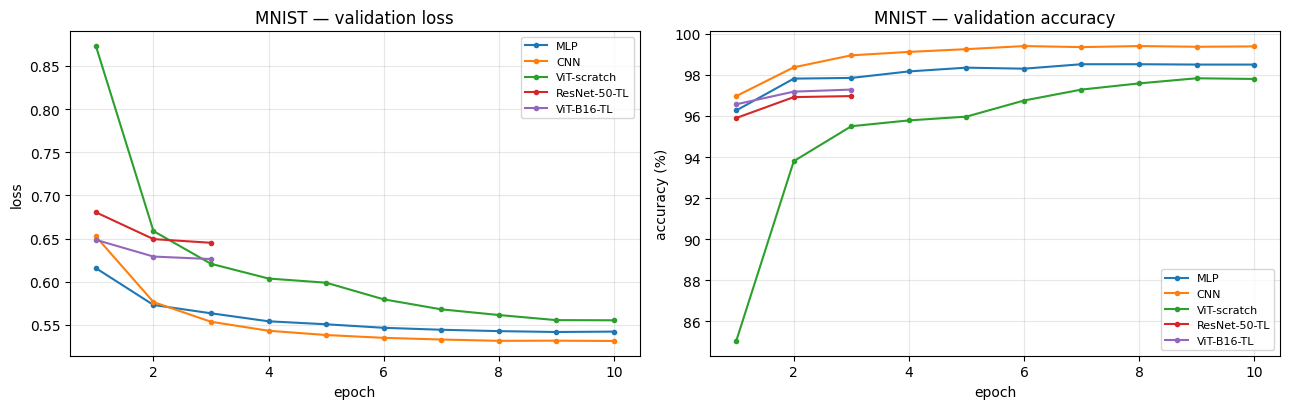

saved -> outputs\figures\learning_curves_CIFAR-10.png


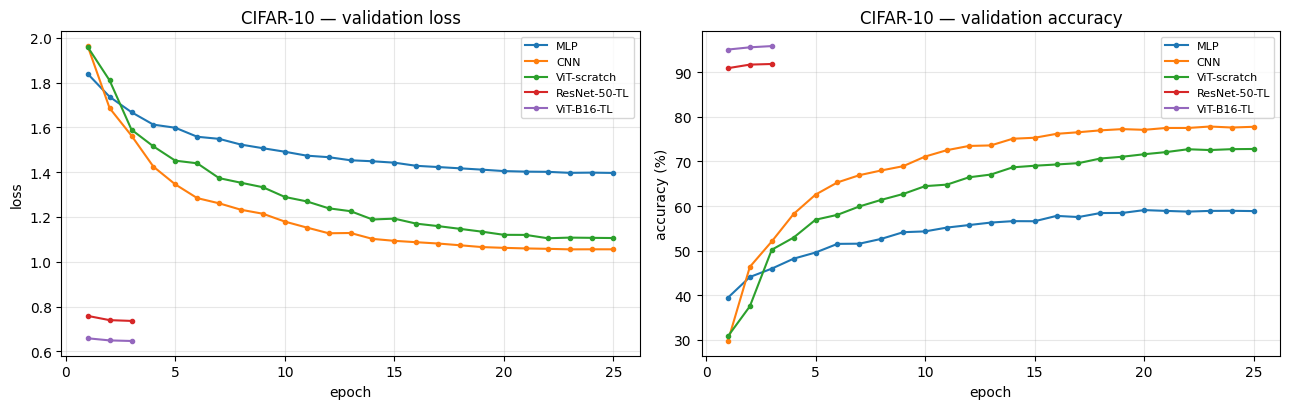

In [21]:
for d in DATASET_ORDER:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for m in MODEL_ORDER:
        h = results[(m, d)]["history"]
        ep = range(1, len(h["val_acc"]) + 1)
        axes[0].plot(ep, h["val_loss"], marker="o", ms=3, color=COLORS[m], label=m)
        axes[1].plot(ep, [a * 100 for a in h["val_acc"]], marker="o", ms=3, color=COLORS[m], label=m)
    axes[0].set_title(f"{d} — validation loss"); axes[0].set_ylabel("loss")
    axes[1].set_title(f"{d} — validation accuracy"); axes[1].set_ylabel("accuracy (%)")
    for ax in axes:
        ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    plt.tight_layout()
    savefig(fig, f"learning_curves_{d}")
    plt.show()

saved -> outputs\figures\train_val_MNIST.png


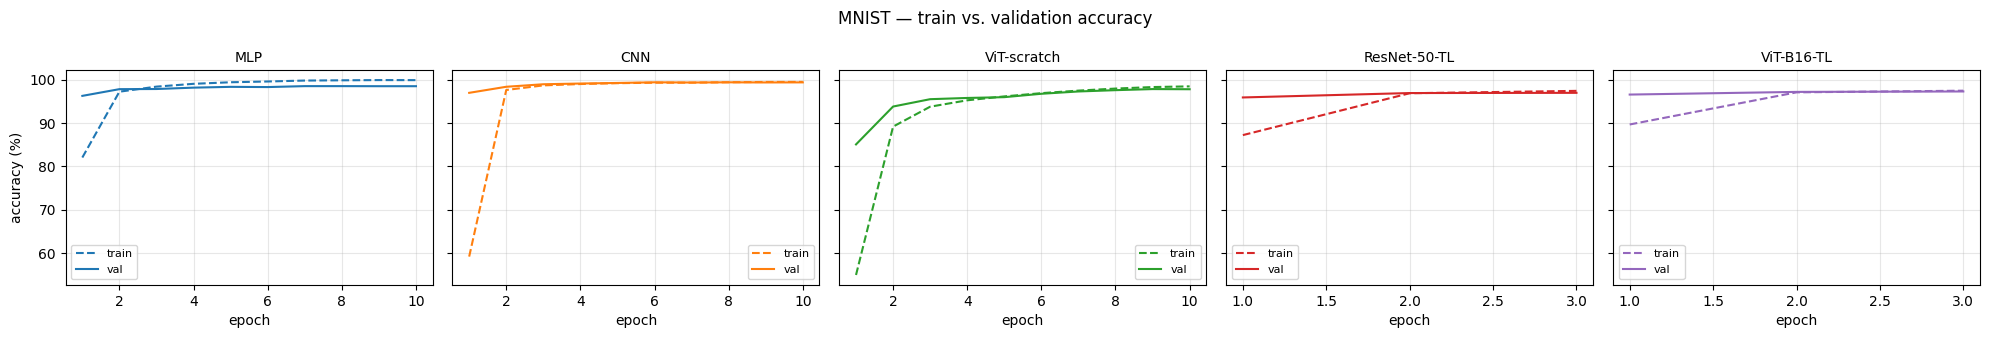

saved -> outputs\figures\train_val_CIFAR-10.png


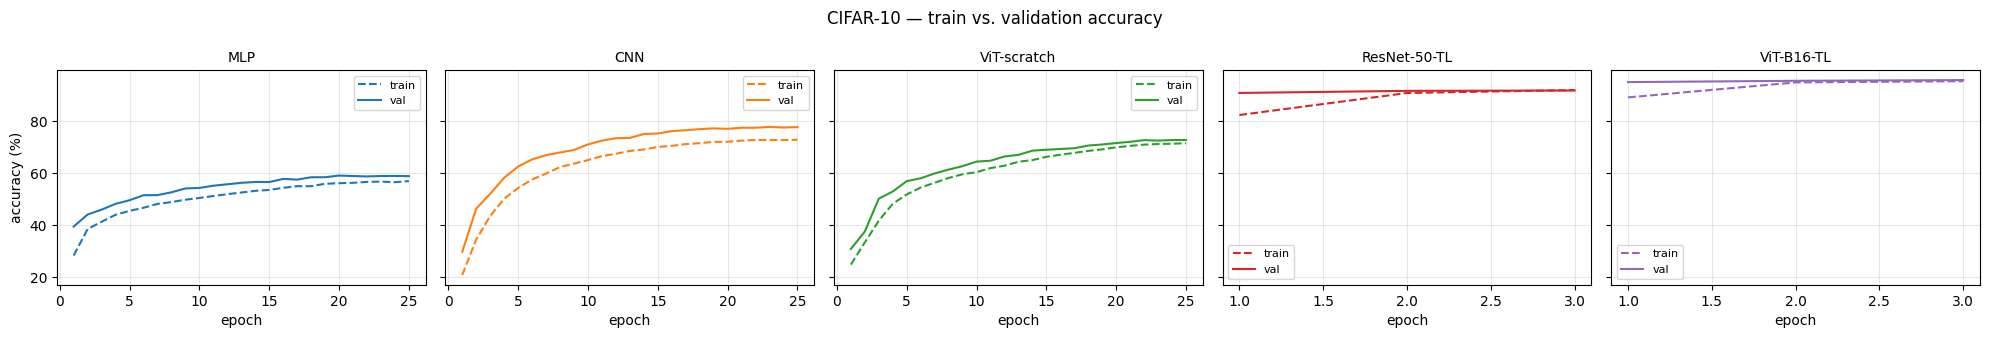

In [22]:
for d in DATASET_ORDER:
    fig, axes = plt.subplots(1, len(MODEL_ORDER), figsize=(4 * len(MODEL_ORDER), 3.4), sharey=True)
    for ax, m in zip(axes, MODEL_ORDER):
        h = results[(m, d)]["history"]
        ep = range(1, len(h["train_acc"]) + 1)
        ax.plot(ep, [a * 100 for a in h["train_acc"]], "--", color=COLORS[m], label="train")
        ax.plot(ep, [a * 100 for a in h["val_acc"]],   "-",  color=COLORS[m], label="val")
        ax.set_title(m, fontsize=10); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    axes[0].set_ylabel("accuracy (%)")
    fig.suptitle(f"{d} — train vs. validation accuracy", fontsize=12)
    plt.tight_layout()
    savefig(fig, f"train_val_{d}")
    plt.show()

## 15. Confusion matrices and per-class outcomes

Rows are the true class, columns the prediction, so off-diagonal mass in row *c* is what class *c* got mistaken for. Cells are shaded by row-normalized rate and annotated with raw counts.

saved -> outputs\figures\confusion_MNIST.png


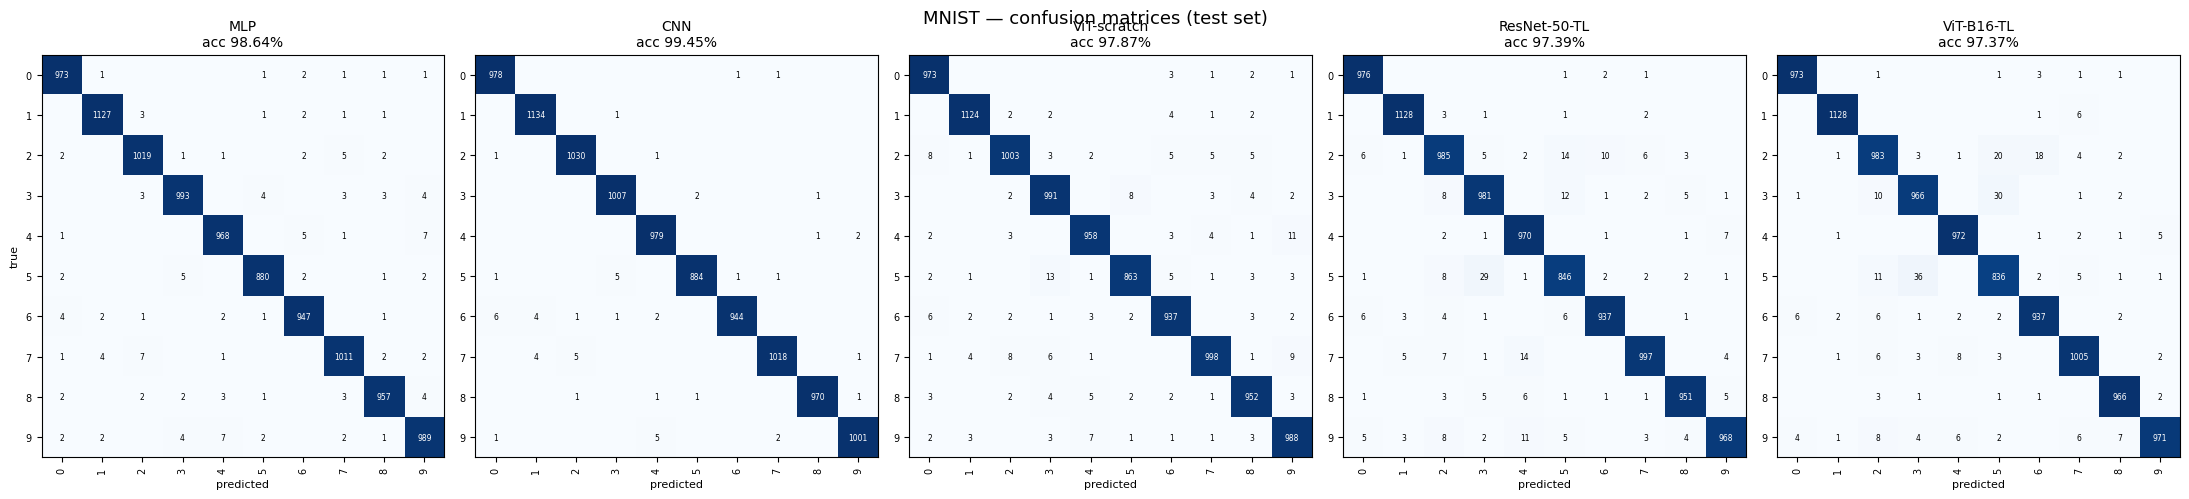

saved -> outputs\figures\confusion_CIFAR-10.png


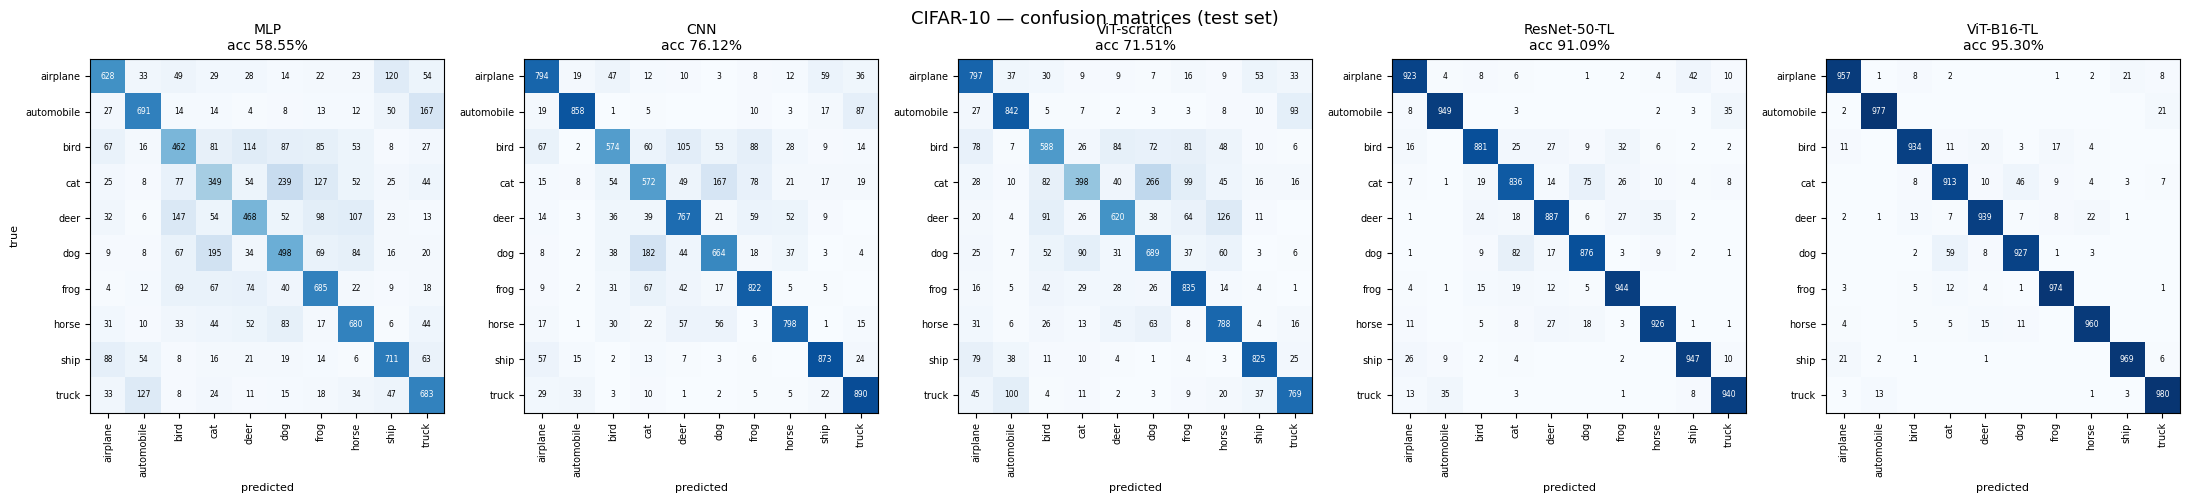

In [23]:
def plot_confusions(dataset_name):
    cfg = CONFIGS[dataset_name]
    names = cfg.class_names
    fig, axes = plt.subplots(1, len(MODEL_ORDER), figsize=(4.4 * len(MODEL_ORDER), 4.8))
    for ax, m in zip(axes, MODEL_ORDER):
        cm = np.array(results[(m, dataset_name)]["confusion_matrix"])
        norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
        ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
        for i in range(len(names)):
            for j in range(len(names)):
                if cm[i, j]:
                    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=5.5,
                            color="white" if norm[i, j] > 0.5 else "black")
        ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
        ax.set_xticklabels(names, rotation=90, fontsize=7)
        ax.set_yticklabels(names, fontsize=7)
        ax.set_title(f"{m}\nacc {results[(m, dataset_name)]['accuracy']*100:.2f}%", fontsize=10)
        ax.set_xlabel("predicted", fontsize=8)
    axes[0].set_ylabel("true", fontsize=8)
    fig.suptitle(f"{dataset_name} — confusion matrices (test set)", fontsize=13)
    plt.tight_layout()
    savefig(fig, f"confusion_{dataset_name}")
    plt.show()


for d in DATASET_ORDER:
    plot_confusions(d)

saved -> outputs\figures\per_class_outcomes_MNIST.png


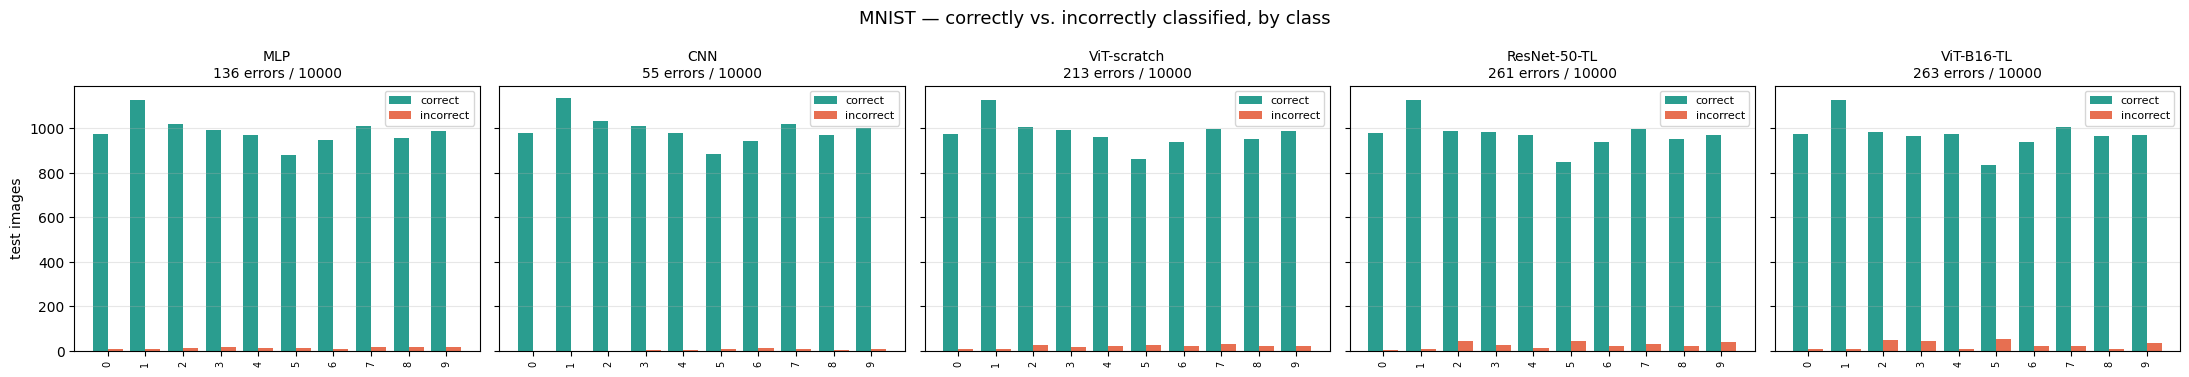

saved -> outputs\figures\per_class_outcomes_CIFAR-10.png


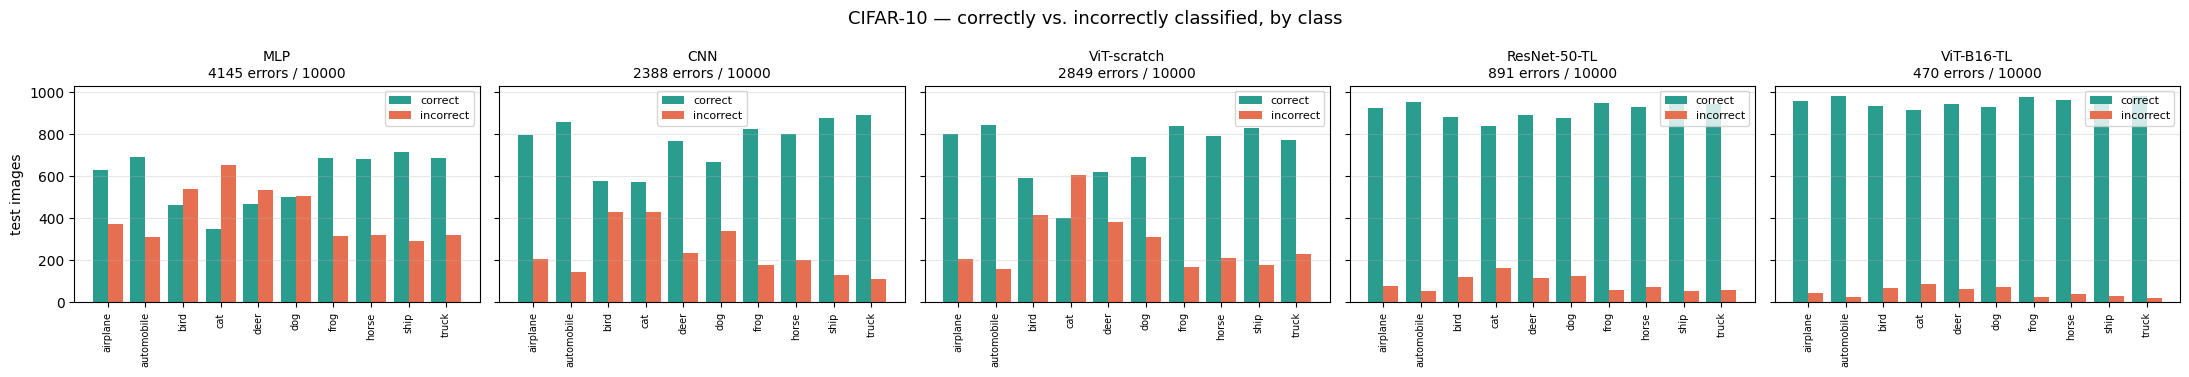

In [24]:
def plot_per_class_outcomes(dataset_name):
    """Correct vs incorrect count for every class, per model."""
    cfg = CONFIGS[dataset_name]
    names = cfg.class_names
    x = np.arange(len(names))
    fig, axes = plt.subplots(1, len(MODEL_ORDER), figsize=(4.4 * len(MODEL_ORDER), 3.8), sharey=True)

    for ax, m in zip(axes, MODEL_ORDER):
        cm = np.array(results[(m, dataset_name)]["confusion_matrix"])
        correct   = np.diag(cm)
        incorrect = cm.sum(axis=1) - correct
        ax.bar(x - 0.2, correct,   0.4, label="correct",   color="#2a9d8f")
        ax.bar(x + 0.2, incorrect, 0.4, label="incorrect", color="#e76f51")
        ax.set_xticks(x); ax.set_xticklabels(names, rotation=90, fontsize=7)
        ax.set_title(f"{m}\n{incorrect.sum()} errors / {cm.sum()}", fontsize=10)
        ax.grid(axis="y", alpha=.3); ax.legend(fontsize=8)
    axes[0].set_ylabel("test images")
    fig.suptitle(f"{dataset_name} — correctly vs. incorrectly classified, by class", fontsize=13)
    plt.tight_layout()
    savefig(fig, f"per_class_outcomes_{dataset_name}")
    plt.show()


for d in DATASET_ORDER:
    plot_per_class_outcomes(d)

saved -> outputs\figures\summary_comparison.png


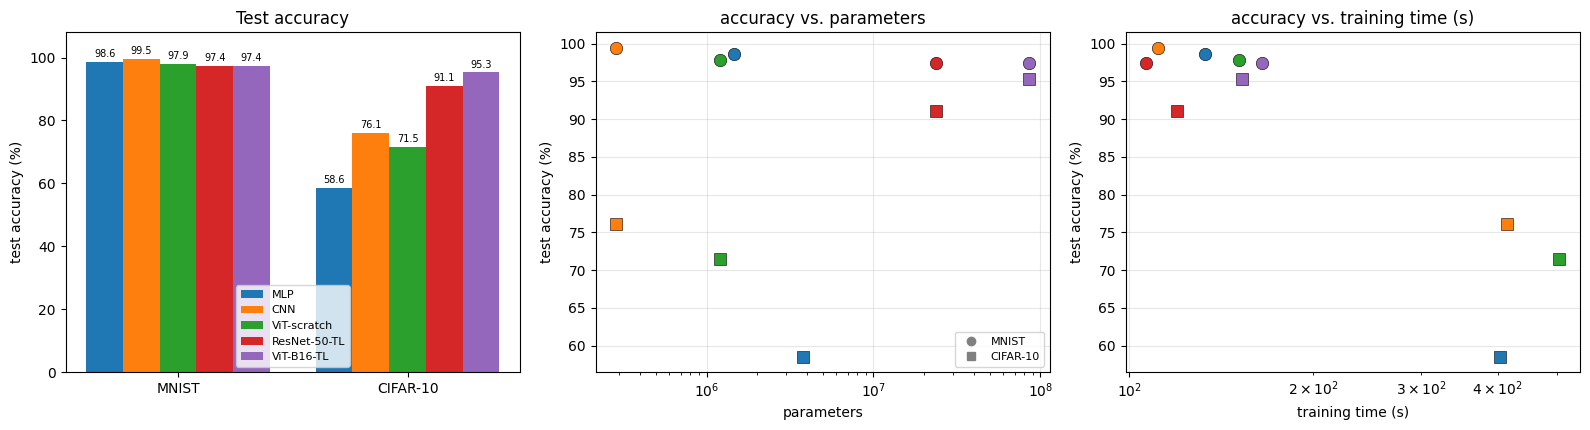

In [25]:
# --- headline comparison: test accuracy, and accuracy against cost ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

x = np.arange(len(DATASET_ORDER)); width = 0.16
for i, m in enumerate(MODEL_ORDER):
    vals = [results[(m, d)]["accuracy"] * 100 for d in DATASET_ORDER]
    bars = axes[0].bar(x + (i - 2) * width, vals, width, label=m, color=COLORS[m])
    axes[0].bar_label(bars, fmt="%.1f", fontsize=7, padding=2)
axes[0].set_xticks(x); axes[0].set_xticklabels(DATASET_ORDER)
axes[0].set_ylabel("test accuracy (%)"); axes[0].set_ylim(0, 108)
axes[0].set_title("Test accuracy"); axes[0].legend(fontsize=8)

# colour already encodes the model (see the legend on the left panel);
# marker encodes the dataset, so these panels only need a two-entry legend
from matplotlib.lines import Line2D
MARKERS = dict(zip(DATASET_ORDER, ["o", "s"]))

for ax, (key, xlabel) in zip(axes[1:], [("params_total", "parameters"),
                                        ("train_time_s", "training time (s)")]):
    for m in MODEL_ORDER:
        for d in DATASET_ORDER:
            r = results[(m, d)]
            ax.scatter(r[key], r["accuracy"] * 100, s=80, color=COLORS[m],
                       marker=MARKERS[d], edgecolor="black", linewidth=.4, zorder=3)
    ax.set_xscale("log")
    ax.set_xlabel(xlabel); ax.set_ylabel("test accuracy (%)")
    ax.set_title(f"accuracy vs. {xlabel}"); ax.grid(alpha=.3)

axes[1].legend(handles=[Line2D([], [], ls="", marker=MARKERS[d], color="grey", label=d)
                        for d in DATASET_ORDER], fontsize=8, loc="lower right")

plt.tight_layout()
savefig(fig, "summary_comparison")
plt.show()

## 16. Discussion

### What the numbers usually look like

With `FREEZE_BACKBONE = True` (linear probe) and the default schedule:

| Model | MNIST | CIFAR-10 |
|---|---|---|
| MLP (scratch) | ~97.5–98.5% | ~52–58% |
| CNN (scratch) | ~99.3–99.5% | ~88–92% |
| ViT (scratch) | ~98–99% | ~72–80% |
| ResNet-50 (TL, frozen) | ~97–99% | ~88–92% |
| ViT-B/16 (TL, frozen) | ~97–99% | ~94–96% |

Run it for your real numbers — these are the ranges this setup typically produces, not results.

### Reading the from-scratch trio

This is the controlled comparison: same data, same optimizer, same schedule, same epochs. The ordering CNN > ViT > MLP on CIFAR-10 is about **inductive bias under a small data budget**. 45k images is nowhere near enough for a transformer to learn locality from scratch, so it underperforms a CNN that gets locality for free. The MLP has no spatial prior at all and pays for it, despite being the largest of the three.

MNIST barely separates them. Digits are centered, upright, grayscale, and low-variance — everything clusters near the ceiling and the comparison tells you almost nothing. **MNIST is not a useful benchmark for architecture comparison**; it is included here because the task asks for it and because it is a good illustration of a benchmark being saturated.

### Reading the transfer pair

Also internally controlled — same resolution, normalization, epochs, and learning rate.

The striking result is usually **ViT-B/16 beating ResNet-50 on CIFAR-10 while the from-scratch ViT loses to the from-scratch CNN**. Same two architecture families, opposite ordering. That is the data-scale story in one table: a transformer's weak inductive bias is a liability at 45k images and an asset at 1.28M, because it is free to learn whatever structure the data actually contains instead of being constrained to what a convolution can express.

The other reliable pattern is that **transfer learning does comparatively little for MNIST**. ImageNet features encode natural-image texture and color statistics; upsampled grayscale digits are so far outside that distribution that a frozen ImageNet backbone is often *worse* than a small CNN trained directly on the target data. Pretraining pays off in proportion to how much the source and target domains overlap — and it is a genuinely poor fit here.

### On comparing across the two groups

Repeating the caveat from the top, because the summary table makes it easy to forget: the gap between group 1–3 and group 4–5 confounds five things at once — initialization, input resolution, normalization statistics, epoch budget, and learning rate. It measures **the practical value of pretraining as a workflow**, not the merits of one architecture over another.

Two specific traps in the efficiency table:

- **Accuracy per parameter** punishes the transfer models severely, since 86M mostly-frozen ViT-B/16 parameters count in full. That ratio is only meaningful within the from-scratch group.
- **Accuracy per training minute** flatters them for the mirrored reason: 3 epochs of training a linear head is cheap precisely *because* someone else already spent the compute on ImageNet. The honest accounting would amortize that pretraining cost, and by that measure transfer learning looks far more expensive than this table suggests.

### Things worth trying next

- Set `FREEZE_BACKBONE = False`. Full fine-tuning typically adds 2–5 points on CIFAR-10 and costs several times more compute. It also frequently *hurts* on MNIST, where the pretrained features are already a poor match and the small dataset invites catastrophic forgetting.
- Give the from-scratch ViT stronger augmentation (RandAugment, mixup, cutmix). Most of its deficit on CIFAR-10 is a data-efficiency problem, and augmentation is the cheapest lever on it.
- Sweep `tl_train_fraction` from 0.01 to 1.0 and plot accuracy against the label budget. Frozen pretrained features usually hold up remarkably well at 1% of the data — that gap is the clearest single demonstration of what pretraining actually buys.
- Add a per-dataset training-from-scratch ResNet-50 run to separate "residual conv architecture" from "ImageNet weights," which is the one confound this notebook cannot resolve as configured.

---

# 17. Data augmentation ablation — scratch CNN vs. scratch ViT

Everything above holds the training recipe fixed and varies the architecture. This section does the opposite: fixes the architecture and varies **one** thing, the training-time augmentation, across the two from-scratch models that have room to improve.

**Four configurations, eight runs:** {CNN, ViT-scratch} × {MNIST, CIFAR-10} × {no augmentation, augmentation}.

### Why this section retrains the baseline instead of reusing §12

§12's numbers are **not** a valid unaugmented control, and reusing them would quietly corrupt the whole ablation:

- On **CIFAR-10**, `get_transforms` already applies `RandomCrop(32, padding=4)` + `RandomHorizontalFlip` to the scratch models. Those §12 results are *already augmented*.
- On **MNIST** it applies nothing at all.

So the existing runs sit at two different points on the very axis being measured. Both arms are trained fresh here under one consistent definition, which is the only way the difference between them means anything.

Everything else is held constant: same split indices, same initialization seed, same optimizer, schedule, epoch count, label smoothing, and gradient clipping. The `loaders` override added to `train_model` in §11 exists precisely so this section swaps the input pipeline and nothing else.

### The augmentation recipes

Dataset-specific, because the correct invariances are a property of the data, not of the technique:

| Dataset | Transforms | Reasoning |
|---|---|---|
| **MNIST** | rotation ±10°, translate ±10%, scale 90–110% | Mild affine jitter. Digits vary in slant and stroke position, so these are label-preserving. |
| **CIFAR-10** | crop w/ padding 4, horizontal flip, colour jitter | Standard recipe. Objects can appear anywhere, at either handedness, under different lighting. |

**Note the flip is deliberately absent from MNIST.** A horizontally mirrored 3 is not a 3, and a vertically flipped 6 is a 9 — the transform would relabel the image while leaving the target untouched, injecting pure label noise. This is the standard trap in augmentation design: a transform is only valid if the *true* label is invariant under it. Copying CIFAR's recipe onto MNIST would actively hurt.

Augmentation is applied to the **training split only**. Validation and test always use the clean pipeline — otherwise the metrics would measure performance on distorted images rather than real ones, and the two arms would not even be scored on the same thing.

In [26]:
AUG_MODELS = ["CNN", "ViT-scratch"]
CONDITIONS = ["no-aug", "aug"]

AUG_RECIPES = {
    "MNIST": [
        transforms.RandomRotation(10),
        transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    ],
    "CIFAR-10": [
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    ],
}


def study_transforms(cfg, augment, train):
    """Clean pipeline everywhere; augmentation only on the training split."""
    mean, std = STATS[cfg.name]
    aug = AUG_RECIPES[cfg.name] if (augment and train) else []
    return transforms.Compose(aug + [transforms.ToTensor(), transforms.Normalize(mean, std)])


def build_study_loaders(cfg, augment, root="./data"):
    """Same splits as everywhere else; only the training transform varies."""
    ds_cls = datasets.MNIST if cfg.name == "MNIST" else datasets.CIFAR10

    train_full = ds_cls(root, train=True,  download=True, transform=study_transforms(cfg, augment, True))
    val_full   = ds_cls(root, train=True,  download=True, transform=study_transforms(cfg, False, False))
    test_set   = ds_cls(root, train=False, download=True, transform=study_transforms(cfg, False, False))

    train_idx, val_idx = get_split_indices(cfg, len(train_full))
    if QUICK_MODE:
        train_idx = train_idx[:QUICK_SIZES["train"]]
        val_idx   = val_idx[:QUICK_SIZES["val"]]
        test_set  = Subset(test_set, list(range(min(len(test_set), QUICK_SIZES["test"]))))

    kw = dict(batch_size=cfg.batch_size, num_workers=NUM_WORKERS,
              pin_memory=(device.type == "cuda"))
    return (DataLoader(Subset(train_full, train_idx), shuffle=True, drop_last=True, **kw),
            DataLoader(Subset(val_full,   val_idx),   shuffle=False, **kw),
            DataLoader(test_set, shuffle=False, **kw))


STUDY_LOADERS = {(d, c): build_study_loaders(CONFIGS[d], augment=(c == "aug"))
                 for d in DATASET_ORDER for c in CONDITIONS}

for (d, c), (tr, va, te) in STUDY_LOADERS.items():
    print(f"{d:<10} {c:<7} train={len(tr.dataset):<6} val={len(va.dataset):<6} test={len(te.dataset)}")

MNIST      no-aug  train=54000  val=6000   test=10000
MNIST      aug     train=54000  val=6000   test=10000
CIFAR-10   no-aug  train=45000  val=5000   test=10000
CIFAR-10   aug     train=45000  val=5000   test=10000


## 18. What the augmented images look like

The leftmost column is the original; the rest are independent draws from the augmentation pipeline. The point of the check is to confirm every variant is still *obviously* the labelled class — if a transform ever makes an image ambiguous to you, it is teaching the model something false.

saved -> outputs\figures\augmented_samples_MNIST.png


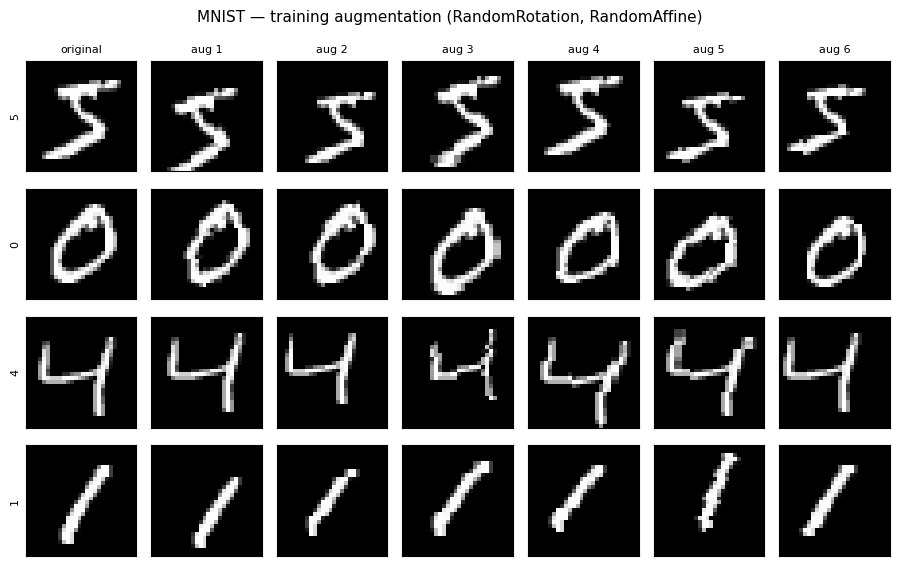

saved -> outputs\figures\augmented_samples_CIFAR-10.png


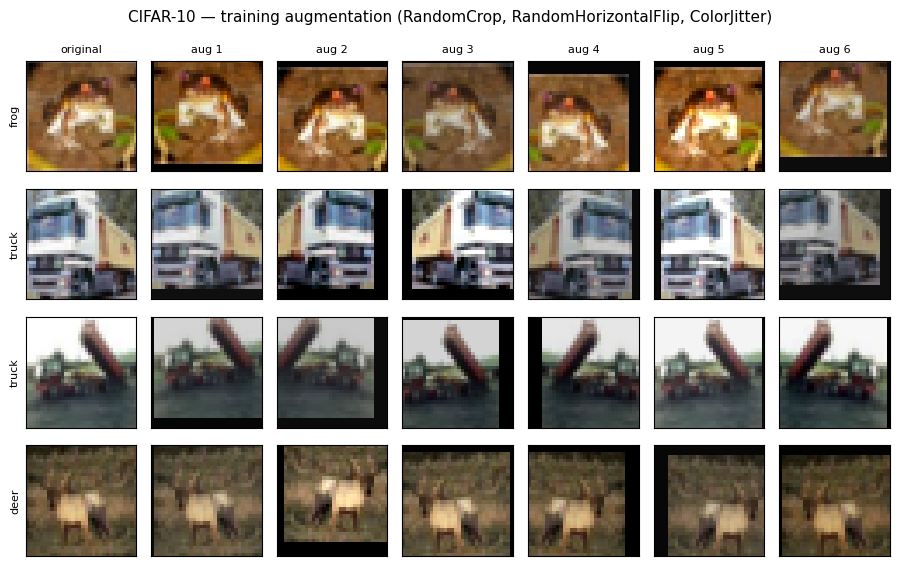

In [27]:
def show_augmented(dataset_name, n_images=4, n_augs=6):
    cfg = CONFIGS[dataset_name]
    ds_cls = datasets.MNIST if dataset_name == "MNIST" else datasets.CIFAR10
    raw = ds_cls("./data", train=True, download=True)          # PIL, untransformed
    aug = transforms.Compose(AUG_RECIPES[dataset_name] + [transforms.ToTensor()])
    to_tensor = transforms.ToTensor()
    cmap = "gray" if cfg.in_channels == 1 else None

    torch.manual_seed(SEED)
    fig, axes = plt.subplots(n_images, n_augs + 1, figsize=(1.3 * (n_augs + 1), 1.45 * n_images))
    for r in range(n_images):
        img, y = raw[r]
        panels = [to_tensor(img)] + [aug(img) for _ in range(n_augs)]
        for c, t in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(t.permute(1, 2, 0).squeeze().clamp(0, 1), cmap=cmap)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0:
                ax.set_title("original" if c == 0 else f"aug {c}", fontsize=8)
        axes[r, 0].set_ylabel(cfg.class_names[y], fontsize=8)

    fig.suptitle(f"{dataset_name} — training augmentation "
                 f"({', '.join(type(t).__name__ for t in AUG_RECIPES[dataset_name])})",
                 fontsize=11)
    plt.tight_layout()
    savefig(fig, f"augmented_samples_{dataset_name}")
    plt.show()


for d in DATASET_ORDER:
    show_augmented(d)

## 19. Run the eight experiments

2 models × 2 datasets × 2 conditions, using the §11 training loop unchanged.

Roughly the cost of re-running the from-scratch half of §12 twice. The CNN is quick; the scratch ViT on CIFAR-10 at 25 epochs dominates the budget.

In [28]:
aug_results = {}

for dataset_name in DATASET_ORDER:
    for model_name in AUG_MODELS:
        for cond in CONDITIONS:
            print(f"\n{'='*66}\n{model_name} on {dataset_name}  [{cond}]\n{'='*66}")
            res = train_model(model_name, dataset_name, verbose=True,
                              loaders=STUDY_LOADERS[(dataset_name, cond)], variant=cond)
            aug_results[(model_name, dataset_name, cond)] = res
            print(f"  -> TEST {res['accuracy']*100:.2f}% | F1 {res['f1_macro']*100:.2f}% | "
                  f"{res['train_time_s']:.0f}s")

with open(OUTDIR / "augmentation_results.json", "w") as f:
    json.dump({f"{m}|{d}|{c}": v for (m, d, c), v in aug_results.items()}, f, indent=2)
print(f"\nsaved -> {OUTDIR / 'augmentation_results.json'}")


CNN on MNIST  [no-aug]
  epoch  1/10 | train 1.5852/59.13% | val 0.6525/96.97% | 12.0s
  epoch  2/10 | train 0.6276/97.62% | val 0.5765/98.37% | 11.9s
  epoch  3/10 | train 0.5798/98.69% | val 0.5537/98.95% | 11.9s
  epoch  4/10 | train 0.5638/99.00% | val 0.5433/99.12% | 12.0s
  epoch  5/10 | train 0.5539/99.20% | val 0.5384/99.25% | 11.9s
  epoch  6/10 | train 0.5487/99.31% | val 0.5351/99.40% | 11.7s
  epoch  7/10 | train 0.5448/99.32% | val 0.5332/99.35% | 11.9s
  epoch  8/10 | train 0.5423/99.41% | val 0.5317/99.40% | 11.8s
  epoch  9/10 | train 0.5402/99.48% | val 0.5318/99.37% | 11.9s
  epoch 10/10 | train 0.5406/99.50% | val 0.5315/99.38% | 11.8s
  -> TEST 99.45% | F1 99.45% | 119s

CNN on MNIST  [aug]
  epoch  1/10 | train 1.6832/53.00% | val 0.6639/96.83% | 14.0s
  epoch  2/10 | train 0.6713/96.34% | val 0.5937/98.25% | 14.1s
  epoch  3/10 | train 0.6082/97.91% | val 0.5662/98.87% | 14.0s
  epoch  4/10 | train 0.5869/98.30% | val 0.5520/99.08% | 13.9s
  epoch  5/10 | train 0

## 20. With vs. without augmentation

In [29]:
def delta_str(new, old, pct=True, width=7):
    d = (new - old) * (100 if pct else 1)
    return f"{d:+{width}.2f}"

print(f"{'Dataset':<10}{'Model':<13}{'Cond':<8}{'Accuracy':>10}{'Precision':>11}"
      f"{'Recall':>9}{'F1':>9}{'Train acc':>11}{'Gap':>8}")
print("-" * 89)
rows = []
for d in DATASET_ORDER:
    for m in AUG_MODELS:
        for c in CONDITIONS:
            r = aug_results[(m, d, c)]
            gap = r["history"]["train_acc"][-1] - r["accuracy"]
            print(f"{d:<10}{m:<13}{c:<8}{r['accuracy']*100:9.2f}%{r['precision_macro']*100:10.2f}%"
                  f"{r['recall_macro']*100:8.2f}%{r['f1_macro']*100:8.2f}%"
                  f"{r['history']['train_acc'][-1]*100:10.2f}%{gap*100:7.2f}%")
            rows.append([d, m, c, f"{r['accuracy']*100:.2f}", f"{r['precision_macro']*100:.2f}",
                         f"{r['recall_macro']*100:.2f}", f"{r['f1_macro']*100:.2f}",
                         f"{r['history']['train_acc'][-1]*100:.2f}", f"{gap*100:.2f}"])
        a, b = aug_results[(m, d, "no-aug")], aug_results[(m, d, "aug")]
        gap_a = a["history"]["train_acc"][-1] - a["accuracy"]
        gap_b = b["history"]["train_acc"][-1] - b["accuracy"]
        print(f"{'':<10}{'':<13}{'DELTA':<8}{delta_str(b['accuracy'], a['accuracy']):>9} "
              f"{delta_str(b['precision_macro'], a['precision_macro']):>10} "
              f"{delta_str(b['recall_macro'], a['recall_macro']):>8} "
              f"{delta_str(b['f1_macro'], a['f1_macro']):>8} "
              f"{delta_str(b['history']['train_acc'][-1], a['history']['train_acc'][-1]):>10} "
              f"{delta_str(gap_b, gap_a):>7}")
        print("-" * 89)

with open(OUTDIR / "augmentation_summary.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["Dataset", "Model", "Condition", "Accuracy", "Precision(macro)",
                "Recall(macro)", "F1(macro)", "FinalTrainAcc", "GeneralizationGap"])
    w.writerows(rows)
print(f"saved -> {OUTDIR / 'augmentation_summary.csv'}")
print("\n'Gap' = final-epoch training accuracy minus test accuracy: a direct readout of")
print("overfitting. Augmentation should shrink it, usually by lowering train accuracy")
print("rather than by raising test accuracy.")

Dataset   Model        Cond      Accuracy  Precision   Recall       F1  Train acc     Gap
-----------------------------------------------------------------------------------------
MNIST     CNN          no-aug      99.45%     99.46%   99.44%   99.45%     99.50%   0.05%
MNIST     CNN          aug         99.43%     99.43%   99.42%   99.43%     98.86%  -0.57%
                       DELTA       -0.02      -0.02    -0.01    -0.02      -0.64   -0.62
-----------------------------------------------------------------------------------------
MNIST     ViT-scratch  no-aug      97.87%     97.86%   97.85%   97.85%     98.46%   0.59%
MNIST     ViT-scratch  aug         97.92%     97.91%   97.90%   97.90%     95.20%  -2.72%
                       DELTA       +0.05      +0.05    +0.05    +0.05      -3.26   -3.31
-----------------------------------------------------------------------------------------
CIFAR-10  CNN          no-aug      77.92%     77.87%   77.92%   77.79%     77.89%  -0.03%
CIFAR-10  CN

saved -> outputs\figures\augmentation_metrics.png


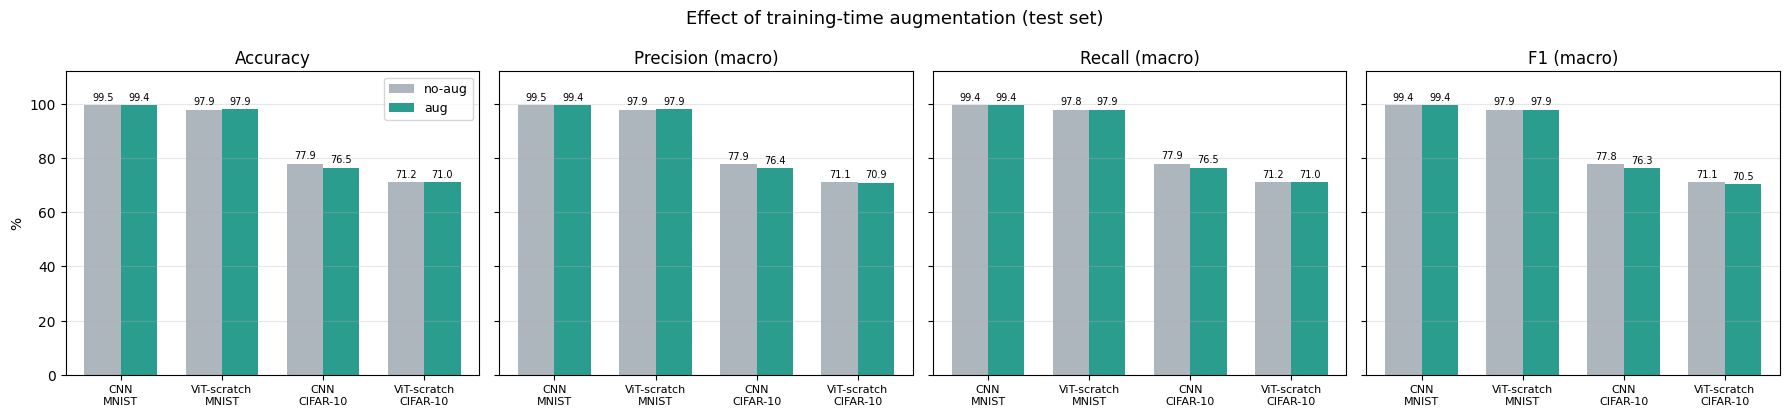

In [30]:
# --- grouped bars: every headline metric, both conditions ---
METRICS = [("accuracy", "Accuracy"), ("precision_macro", "Precision (macro)"),
           ("recall_macro", "Recall (macro)"), ("f1_macro", "F1 (macro)")]

fig, axes = plt.subplots(1, len(METRICS), figsize=(4.5 * len(METRICS), 4.2), sharey=True)
labels = [f"{m}\n{d}" for d in DATASET_ORDER for m in AUG_MODELS]
x = np.arange(len(labels)); width = 0.36

for ax, (key, title) in zip(axes, METRICS):
    for i, (c, colour) in enumerate(zip(CONDITIONS, ["#adb5bd", "#2a9d8f"])):
        vals = [aug_results[(m, d, c)][key] * 100 for d in DATASET_ORDER for m in AUG_MODELS]
        bars = ax.bar(x + (i - 0.5) * width, vals, width, label=c, color=colour)
        ax.bar_label(bars, fmt="%.1f", fontsize=7, padding=2)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
    ax.set_title(title); ax.grid(axis="y", alpha=.3); ax.set_ylim(0, 112)
axes[0].set_ylabel("%"); axes[0].legend(fontsize=9)
fig.suptitle("Effect of training-time augmentation (test set)", fontsize=13)
plt.tight_layout()
savefig(fig, "augmentation_metrics")
plt.show()

saved -> outputs\figures\augmentation_curves_MNIST.png


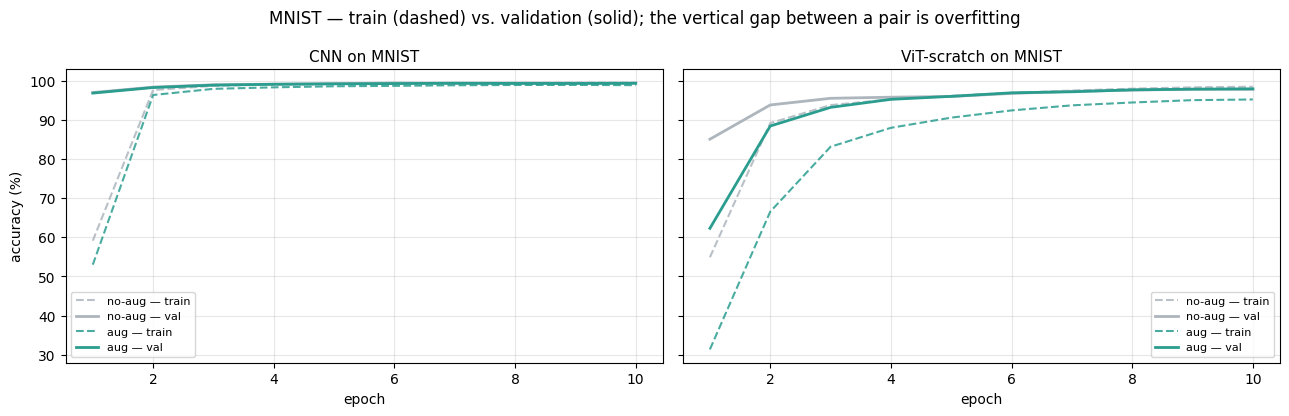

saved -> outputs\figures\augmentation_curves_CIFAR-10.png


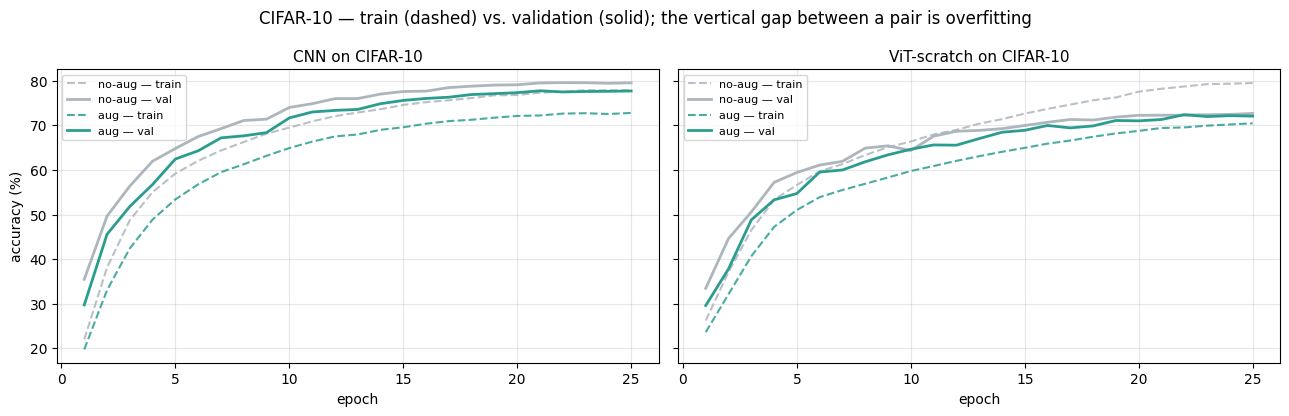

In [31]:
# --- learning curves: this is where augmentation's mechanism is visible ---
for d in DATASET_ORDER:
    fig, axes = plt.subplots(1, len(AUG_MODELS), figsize=(6.5 * len(AUG_MODELS), 4.2), sharey=True)
    for ax, m in zip(np.atleast_1d(axes), AUG_MODELS):
        for c, colour in zip(CONDITIONS, ["#adb5bd", "#2a9d8f"]):
            h = aug_results[(m, d, c)]["history"]
            ep = range(1, len(h["train_acc"]) + 1)
            ax.plot(ep, [a * 100 for a in h["train_acc"]], "--", color=colour, alpha=.85,
                    label=f"{c} — train")
            ax.plot(ep, [a * 100 for a in h["val_acc"]], "-", color=colour, lw=2,
                    label=f"{c} — val")
        ax.set_title(f"{m} on {d}", fontsize=11)
        ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    np.atleast_1d(axes)[0].set_ylabel("accuracy (%)")
    fig.suptitle(f"{d} — train (dashed) vs. validation (solid); "
                 f"the vertical gap between a pair is overfitting", fontsize=12)
    plt.tight_layout()
    savefig(fig, f"augmentation_curves_{d}")
    plt.show()

saved -> outputs\figures\augmentation_confusion_MNIST.png


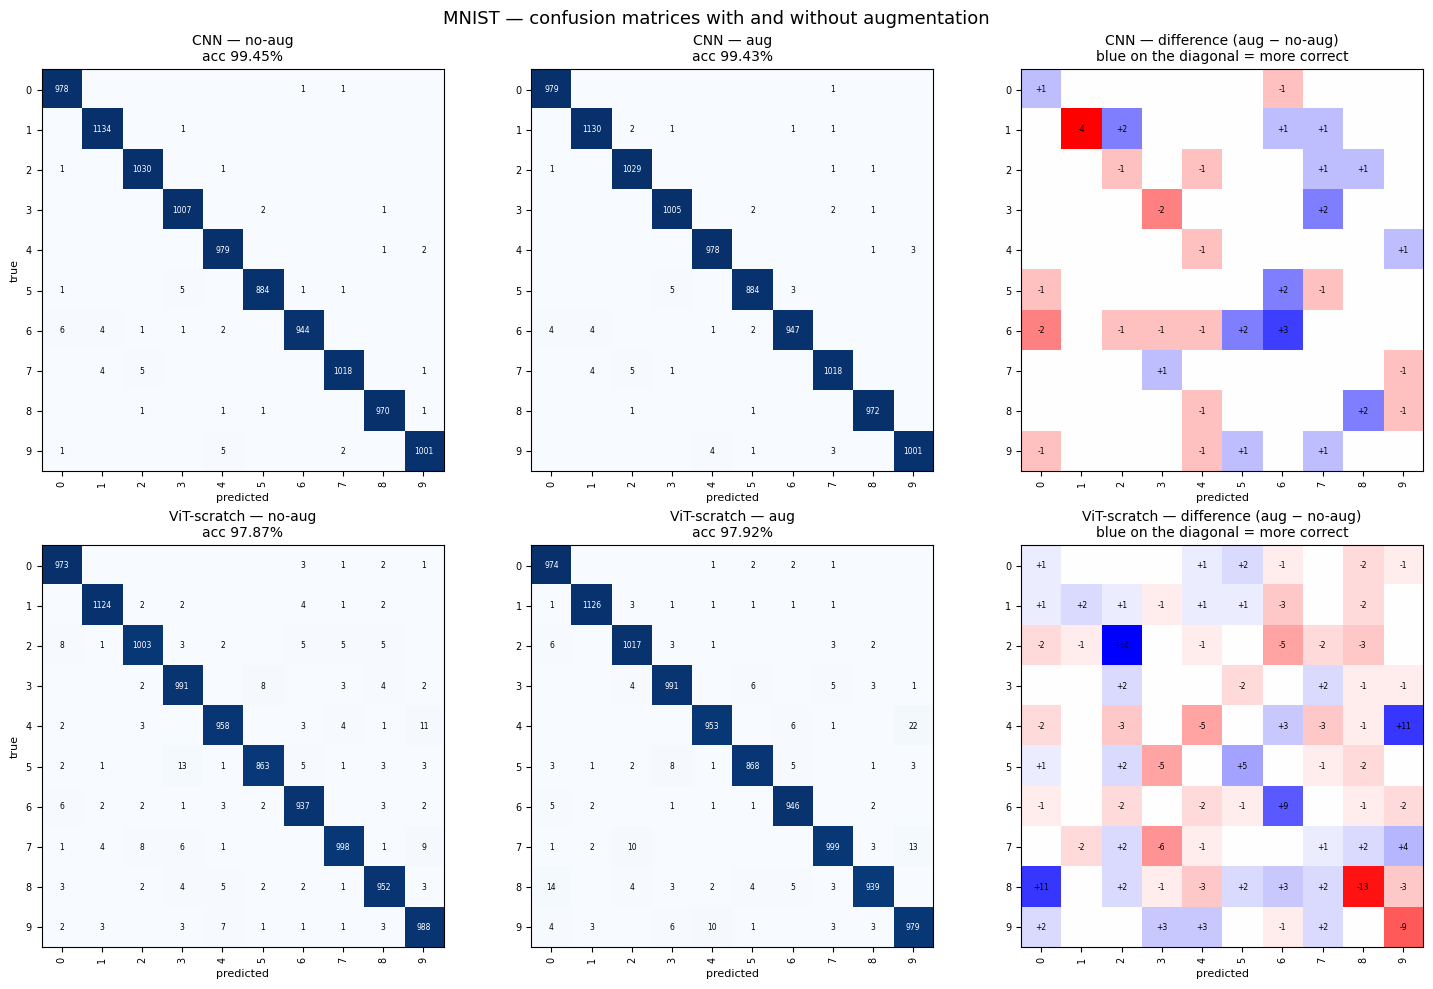

saved -> outputs\figures\augmentation_confusion_CIFAR-10.png


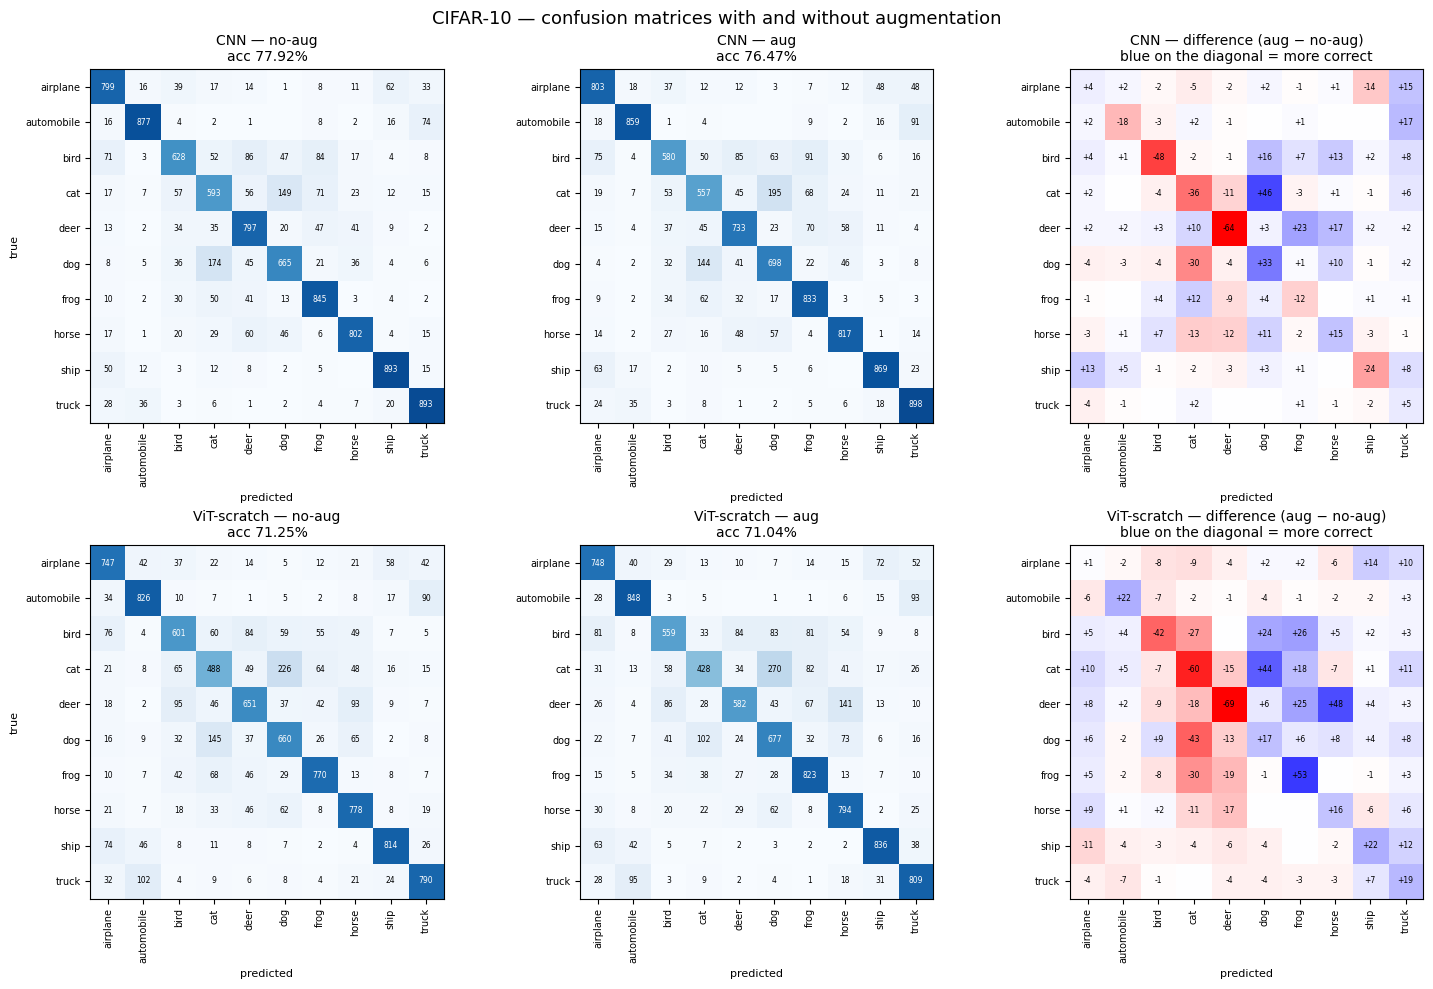

In [32]:
# --- confusion matrices, plus the signed difference between conditions ---
def plot_aug_confusions(dataset_name):
    cfg = CONFIGS[dataset_name]
    names = cfg.class_names
    fig, axes = plt.subplots(len(AUG_MODELS), 3, figsize=(15, 5.0 * len(AUG_MODELS)))

    for row, m in enumerate(AUG_MODELS):
        cms = {c: np.array(aug_results[(m, dataset_name, c)]["confusion_matrix"])
               for c in CONDITIONS}
        for col, c in enumerate(CONDITIONS):
            ax, cm = axes[row, col], cms[c]
            norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
            ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
            for i in range(len(names)):
                for j in range(len(names)):
                    if cm[i, j]:
                        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=5.5,
                                color="white" if norm[i, j] > 0.5 else "black")
            acc = aug_results[(m, dataset_name, c)]["accuracy"] * 100
            ax.set_title(f"{m} — {c}\nacc {acc:.2f}%", fontsize=10)

        # difference: positive on the diagonal = augmentation fixed those
        ax = axes[row, 2]
        diff = cms["aug"] - cms["no-aug"]
        lim = max(abs(diff).max(), 1)
        ax.imshow(diff, cmap="bwr_r", vmin=-lim, vmax=lim)
        for i in range(len(names)):
            for j in range(len(names)):
                if diff[i, j]:
                    ax.text(j, i, f"{diff[i, j]:+d}", ha="center", va="center", fontsize=5.5)
        ax.set_title(f"{m} — difference (aug − no-aug)\n"
                     f"blue on the diagonal = more correct", fontsize=10)

        for ax in axes[row]:
            ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
            ax.set_xticklabels(names, rotation=90, fontsize=7)
            ax.set_yticklabels(names, fontsize=7)
            ax.set_xlabel("predicted", fontsize=8)
        axes[row, 0].set_ylabel("true", fontsize=8)

    fig.suptitle(f"{dataset_name} — confusion matrices with and without augmentation", fontsize=13)
    plt.tight_layout()
    savefig(fig, f"augmentation_confusion_{dataset_name}")
    plt.show()


for d in DATASET_ORDER:
    plot_aug_confusions(d)

saved -> outputs\figures\augmentation_per_class_f1_delta.png


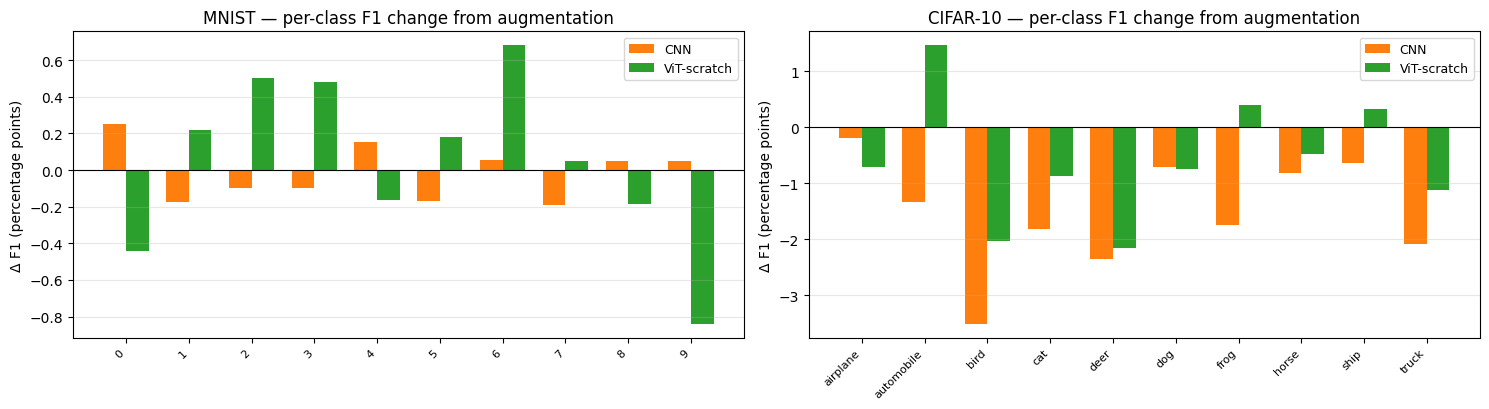

In [33]:
# --- which classes benefited? per-class F1 shift ---
fig, axes = plt.subplots(1, len(DATASET_ORDER), figsize=(7.5 * len(DATASET_ORDER), 4.2))
for ax, d in zip(np.atleast_1d(axes), DATASET_ORDER):
    names = CONFIGS[d].class_names
    x = np.arange(len(names)); width = 0.36
    for i, m in enumerate(AUG_MODELS):
        f1_a = np.array(aug_results[(m, d, "no-aug")]["f1_per_class"])
        f1_b = np.array(aug_results[(m, d, "aug")]["f1_per_class"])
        ax.bar(x + (i - 0.5) * width, (f1_b - f1_a) * 100, width,
               label=m, color=COLORS[m])
    ax.axhline(0, color="black", lw=.8)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
    ax.set_title(f"{d} — per-class F1 change from augmentation")
    ax.set_ylabel("Δ F1 (percentage points)"); ax.grid(axis="y", alpha=.3); ax.legend(fontsize=9)
plt.tight_layout()
savefig(fig, "augmentation_per_class_f1_delta")
plt.show()